# Interpretable Equations for CMP Removal Rate: a Symbolic Regression Study
### PHM Society 2016 Data Challenge — Notebook 2 of 2

**Goal.** Find short, human-readable equations that predict a wafer's average material removal rate (MRR). Check whether they compete with black-box models, whether they make physical sense, and whether they hold up on data the search never saw.

**Prerequisite.** Run *Notebook 1* first. It produces `outputs/run_features.csv` and `outputs/labels.csv`, which this notebook reads.

---

## Executive summary

This study searches for compact equations that predict a run's removal rate from (i) recorded process settings, (ii) consumable wear and (iii) the recent removal-rate level (drift). Two independent symbolic-regression engines are used, and results are compared against physical and black-box baselines under two evaluation protocols: the official benchmark split, with test labels sealed until every model is frozen, and a stricter forward-in-time split.

The results depend on the machine the notebook runs on (whether PySR is available, the runtime preset, PySR's stochastic search). The summary of findings is therefore **generated from the live run** at the start of §15 and saved to `outputs/sr/summary.md`, rather than written here by hand. The hypotheses being tested are listed in §1.

## Contents
1. What symbolic regression is, and the questions this study tests
2. Setup and configuration
3. Data, variables and scaling
4. Evaluation protocols (and how the test set is kept sealed)
5. Baselines
6. Symbolic regression engines
7. Running the searches
8. Pareto fronts and model selection
9. The selected equations
10. Stability: are the same equations rediscovered?
11. Physical plausibility and behaviour of the equations
12. Freezing the models
13. Final evaluation on held-out data (opened once)
14. Residual diagnostics
15. Conclusions, limitations and next steps
16. Exports

## 1. What symbolic regression is, and the questions this study tests

**Symbolic regression (SR)** searches the space of mathematical expressions built from variables, constants and operators (`+ − × ÷`, `√`, `log`, …) for formulas that fit the data. Ordinary regression fixes the formula and fits its coefficients; SR searches over the formula itself. Every candidate trades **accuracy** against **complexity** (the number of nodes in its expression tree), so the output is a **Pareto front**: the most accurate equation at each complexity. Picking from that front is a modelling decision, made here with a rule fixed in advance (§8).

Two engines are used, so that conclusions don't depend on one algorithm:

| Engine | Method | Why |
|---|---|---|
| **PySR** (Cranmer, 2023) | Multi-population genetic programming with simulated annealing, constant optimisation and a parsimony pressure; backend in Julia | State-of-the-art general SR; can find nested, non-linear forms |
| **Sparse library SR** (built in, SISSO/SINDy-style) | Builds a library of candidate terms (x, x², √x, log x, 1/x, xᵢxⱼ, xᵢ/xⱼ), then selects the best sparse linear combination by forward stepwise regression | Deterministic, fast, needs no Julia; exhaustive within its library |

If PySR cannot be installed on a machine, the notebook still runs end to end with the built-in engine and says so.

**Hypotheses carried over from Notebook 1**

| # | Hypothesis | Evidence from Notebook 1 | How it is tested here |
|---|---|---|---|
| H1 | Pressure/speed (Preston) terms add little within a mode | Preston slope ≈ 0 (§14); no detrended association (§13) | Equations from *physics-only* inputs vs a per-mode constant |
| H2 | Wear (especially dresser usage) adds real but modest skill | Dresser partial ρ ≈ −0.4; wear explains 24–33% (§12) | *Physics + wear* inputs vs *physics only* |
| H3 | Recent removal-rate history (drift level) carries most of the skill | Drift level R² 0.47–0.84 (§11) | *Physics + wear + drift* inputs |
| H4 | Short equations can match black-box accuracy given the same inputs | — | SR vs gradient boosting on identical inputs |
| H5 | Skill holds when predicting the **future**, not just interleaved runs | Splits interleave in time (§5.7) | Separate forward-in-time protocol |

## 2. Setup and configuration

**Runtime presets.** PySR searches dominate the running time. `PRESET = 'quick'` runs one seed with a short search (about 10–25 minutes on a typical laptop). `'standard'` (the default) uses two seeds and longer searches (about 30–90 minutes). `'thorough'` uses three seeds and the longest searches. Every finished search is cached in `outputs/sr/cache/`: re-running the notebook reuses them, and an interrupted run continues where it stopped.

**Installing PySR (first run only).** `pip install pysr`. The first `import pysr` downloads and installs Julia plus PySR's Julia packages automatically (a few hundred MB; 5–15 minutes, needs internet). If that fails, behind a proxy for example, set `USE_PYSR = False` and the notebook uses only the built-in engine.

In [1]:
import os, sys, json, time, re, math, hashlib, platform, warnings, inspect, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')

PRESET = 'standard'          # 'quick' | 'standard' | 'thorough'
USE_PYSR = True              # set False to skip PySR (built-in engine only)
REPRODUCIBLE_PYSR = False    # True = single-threaded deterministic PySR (bit-reproducible, ~3-5x slower)

PRESETS = {
    'quick':    {'seeds': [11],           'niterations': 30,  'populations': 12, 'population_size': 30, 'bootstraps': 20},
    'standard': {'seeds': [11, 22],       'niterations': 80,  'populations': 15, 'population_size': 33, 'bootstraps': 40},
    'thorough': {'seeds': [11, 22, 33],   'niterations': 200, 'populations': 20, 'population_size': 40, 'bootstraps': 100},
}
CONFIG = {
    'seed': 2016, 'preset': PRESET, **PRESETS[PRESET],
    'maxsize': 20,                     # largest expression (nodes) PySR may build
    'binary_operators': ['+', '-', '*', '/'],
    'unary_operators': ['sqrt', 'square', 'log'],
    'sparse_max_terms': 6,             # largest sparse-library equation (terms)
    'selection_tolerance': 0.05,       # pick the simplest equation within 5% of the best selection RMSE
    'drift_neighbours': 10,            # as in Notebook 1
    'forward_fit_end_day': 40.0,       # forward-in-time protocol boundaries (days)
    'forward_select_end_day': 50.0,
    'bootstrap_draws': 2000,
}
RNG = np.random.default_rng(CONFIG['seed'])

HERE = Path.cwd()
OUT = HERE / 'outputs'
SR = OUT / 'sr'; CACHE = SR / 'cache'; FIG = SR / 'figures'
for d in (SR, CACHE, FIG): d.mkdir(parents=True, exist_ok=True)
assert (OUT / 'run_features.csv').exists() and (OUT / 'labels.csv').exists(), \
    'outputs/run_features.csv not found: run Notebook 1 (01_cmp_data_analysis.ipynb) in this folder first.'

MODES = ['A-123', 'A-456', 'B-456']
MODE_COLORS = {'A-123': '#D55E00', 'A-456': '#0072B2', 'B-456': '#009E73'}
TARGET = 'AVG_REMOVAL_RATE'
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.95)
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 11})

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()

print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f"Preset '{PRESET}': {CONFIG['seeds']} seeds x {CONFIG['niterations']} PySR iterations")

Python 3.13.15 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1
Preset 'standard': [11, 22] seeds x 80 PySR iterations


In [2]:
PYSR_OK, PYSR_MSG = False, 'disabled by USE_PYSR = False'
if USE_PYSR:
    os.environ.setdefault('PYTHON_JULIACALL_THREADS', '1' if REPRODUCIBLE_PYSR else 'auto')
    os.environ.setdefault('PYTHON_JULIACALL_HANDLE_SIGNALS', 'yes')
    try:
        t0 = time.time()
        print('Importing PySR (the first time, this installs Julia and its packages - please wait) ...', flush=True)
        import pysr
        from pysr import PySRRegressor
        PYSR_OK, PYSR_MSG = True, f'PySR {getattr(pysr, "__version__", "?")} ready ({time.time() - t0:.0f} s)'
    except Exception as exc:
        PYSR_MSG = f'PySR unavailable -> using the built-in sparse engine only. Reason: {type(exc).__name__}: {str(exc)[:300]}'
try:
    import sympy
    SYMPY_OK = True
except ImportError:
    SYMPY_OK = False
print(PYSR_MSG)
print('SymPy available for equation simplification:', SYMPY_OK)
ENGINES = (['PySR'] if PYSR_OK else []) + ['Sparse']

Importing PySR (the first time, this installs Julia and its packages - please wait) ...
PySR 2.7.0 ready (13 s)
SymPy available for equation simplification: True


## 3. Data, variables and scaling

**Unit of analysis:** one polishing run (`WAFER_ID`, `STAGE`), as in Notebook 1. The four labels flagged there as recording errors (`LABEL_OUTLIER`, values of about 4,200 against a mode median of about 151) are excluded from **every** role. They were flagged on physical grounds before any modelling, and an evaluation dominated by four corrupted labels would measure nothing about the models. The official test set contains no such labels (checked in §13).

**Candidate variables.** Short names keep the equations readable. Each is one representative of a feature cluster from Notebook 1 §13, chosen for physical meaning:

| Name | Source feature | Physical role |
|---|---|---|
| `p_ch` | `PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN` | Head down-force (Preston *P*) |
| `p_ring` | `RETAINER_RING_PRESSURE_ACT_MEAN` | Retainer-ring pressure (edge/pad contact) |
| `w_rot` | `WAFER_ROTATION_ACT_MEAN` | Wafer rotation (Preston *V*) |
| `q_slurry` | `SLURRY_FLOW_LINE_C_ACT_MEAN` | Main slurry flow |
| `t_act` | `ACTIVE_TIME` | Polishing time |
| `u_dresser` | `U_DRESSER_START` | Dresser wear (strongest wear signal in NB1) |
| `u_film` | `U_BACKING_FILM_START` | Backing-film / membrane wear |
| `u_table` | `U_POLISHING_TABLE_START` | Polishing-table counter |
| `drift` | `DRIFT_LEVEL` (recomputed per protocol) | Median rate of the 10 time-nearest *fitting* runs, same mode |

The **dresser-table counter is deliberately excluded**. Notebook 1 showed it is a clock (ρ with time = 1), so an equation using it would be fitting time, not wear.

**Scaling.** Each variable is divided by its median in the fitting data of its mode, so `u_dresser = 1.2` means "20% more dresser usage than typical for this mode". All inputs become dimensionless and positive, which keeps √ and log well defined and makes constants comparable across modes. Missing values (A-123 runs whose signals were never recorded) are filled with the same fitting-data median, so for those runs the equation falls back to its typical-conditions value. This is stated as a limitation in §15.

In [3]:
runs = pd.read_csv(OUT / 'run_features.csv')
labels = pd.read_csv(OUT / 'labels.csv')
dev_labels = labels[labels.SPLIT != 'test'][['RUN_ID', TARGET, 'LABEL_OUTLIER']]   # test labels stay sealed until §13
data = runs.drop(columns=['LABEL_OUTLIER']).merge(dev_labels, on='RUN_ID', how='left', validate='one_to_one')
assert data.loc[data.SPLIT == 'test', TARGET].isna().all(), 'test labels must not be loaded yet'

VARS = {'p_ch': 'PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN', 'p_ring': 'RETAINER_RING_PRESSURE_ACT_MEAN',
        'w_rot': 'WAFER_ROTATION_ACT_MEAN', 'q_slurry': 'SLURRY_FLOW_LINE_C_ACT_MEAN', 't_act': 'ACTIVE_TIME',
        'u_dresser': 'U_DRESSER_START', 'u_film': 'U_BACKING_FILM_START', 'u_table': 'U_POLISHING_TABLE_START'}
EXPERIMENTS = {
    'physics':             ['p_ch', 'p_ring', 'w_rot', 'q_slurry', 't_act'],
    'physics+wear':        ['p_ch', 'p_ring', 'w_rot', 'q_slurry', 't_act', 'u_dresser', 'u_film', 'u_table'],
    'physics+wear+drift':  ['p_ch', 'p_ring', 'w_rot', 'q_slurry', 't_act', 'u_dresser', 'u_film', 'u_table', 'drift'],
}
for short, col in VARS.items(): data[short] = data[col]
print(f'Runs: {len(data):,} | splits: {data.SPLIT.value_counts().to_dict()}')
display(data.groupby('MODE')[list(VARS)].median().round(3))

Runs: 2,829 | splits: {'train': 1981, 'test': 424, 'validation': 424}


,p_ch,p_ring,w_rot,q_slurry,t_act,u_dresser,u_film,u_table
MODE,,,,,,,,
A-123,63.23,"1,450",32.19,282.1,81,481.1,"5,328",144.8
A-456,74.66,"1,515",32.86,421.1,152,385.2,"4,804",161.1
B-456,71.56,"1,531",32.89,424.6,152.3,392.2,"5,318",174.1


## 4. Evaluation protocols (and how the test set is kept sealed)

Every model is built with three strictly separated **roles**:

| Role | Used for | Never used for |
|---|---|---|
| **fit** | Running the search; fitting baseline coefficients; scaling medians; the drift level's reference runs | — |
| **select** | Choosing one equation from each Pareto front; choosing among baseline variants | Fitting |
| **final** | One evaluation of the frozen models | Any decision |

| Protocol | fit | select | final | Question it answers |
|---|---|---|---|---|
| **Official** | official training split | official validation split | official **test** split (labels sealed until §13) | Benchmark performance (runs interleaved in time) |
| **Forward-in-time** | train + validation runs with day < 40 | days 40–50 | days 50–65 | How well do the equations predict the *future*? |

In the forward protocol, the drift level of a select/final run is built only from fitting runs, which by construction lie in the past. A run on day 60 therefore sees a rate history that is 10–20 days old. That is the honest situation for a model that is not updated, and it is exactly what H5 tests.

The official test labels are read in exactly one place (§13), after every model has been frozen and written to disk (§12).

In [4]:
def drift_level(frame, ref, k=CONFIG['drift_neighbours']):
    """Median label of the k time-nearest reference runs of the same mode (excluding the run itself)."""
    out = pd.Series(np.nan, index=frame.index)
    for m in MODES:
        r = ref[ref.MODE == m].sort_values('T_START')
        rt, ry, rid = r.T_START.values, r[TARGET].values, r.RUN_ID.values
        q = frame[frame.MODE == m]
        for i, t, run_id in zip(q.index, q.T_START.values, q.RUN_ID.values):
            j = np.searchsorted(rt, t)
            cand = np.arange(max(0, j - k - 1), min(len(rt), j + k + 1))
            cand = cand[rid[cand] != run_id]
            near = cand[np.argsort(np.abs(rt[cand] - t), kind='stable')[:k]]
            out[i] = np.median(ry[near])
    return out

def make_protocol(name):
    d = data.copy()
    if name == 'official':
        d['ROLE'] = d.SPLIT.map({'train': 'fit', 'validation': 'select', 'test': 'final'})
    else:
        d = d[d.SPLIT != 'test'].copy()
        d['ROLE'] = np.where(d.DAY < CONFIG['forward_fit_end_day'], 'fit',
                             np.where(d.DAY < CONFIG['forward_select_end_day'], 'select', 'final'))
    fit_ref = d[(d.ROLE == 'fit') & ~d.LABEL_OUTLIER.fillna(False).astype(bool)]
    d['drift'] = drift_level(d, fit_ref)
    # per-mode scaling medians from the fitting role only
    med = fit_ref.assign(drift=d.loc[fit_ref.index, 'drift']).groupby('MODE')[list(VARS) + ['drift']].median()
    for v in list(VARS) + ['drift']:
        d[v] = d[v].fillna(d.MODE.map(med[v]))
        d[v + '_r'] = d[v] / d.MODE.map(med[v])
    d = d[~d.LABEL_OUTLIER.fillna(False).astype(bool)]   # labels flagged as recording errors in Notebook 1 are excluded from every role
    return d, med

PROTOCOLS = {}
for pname in ['official', 'forward']:
    d, med = make_protocol(pname)
    PROTOCOLS[pname] = {'data': d, 'scale': med}
    counts = d.groupby(['ROLE', 'MODE']).size().unstack(fill_value=0).reindex(['fit', 'select', 'final'])
    print(f'\nProtocol: {pname}'); display(counts)

# sanity checks on role separation
for pname, P in PROTOCOLS.items():
    d = P['data']
    assert not set(d[d.ROLE == 'fit'].RUN_ID) & set(d[d.ROLE != 'fit'].RUN_ID)
    if pname == 'forward':
        assert d[d.ROLE == 'fit'].DAY.max() < d[d.ROLE == 'select'].DAY.min() <= d[d.ROLE == 'select'].DAY.max() < d[d.ROLE == 'final'].DAY.min()
print('\nRole separation checks passed.')


Protocol: official


MODE,A-123,A-456,B-456
ROLE,,,
fit,364,798,815
select,67,185,172
final,73,165,186



Protocol: forward


MODE,A-123,A-456,B-456
ROLE,,,
fit,264,597,573
select,79,163,184
final,88,223,230



Role separation checks passed.


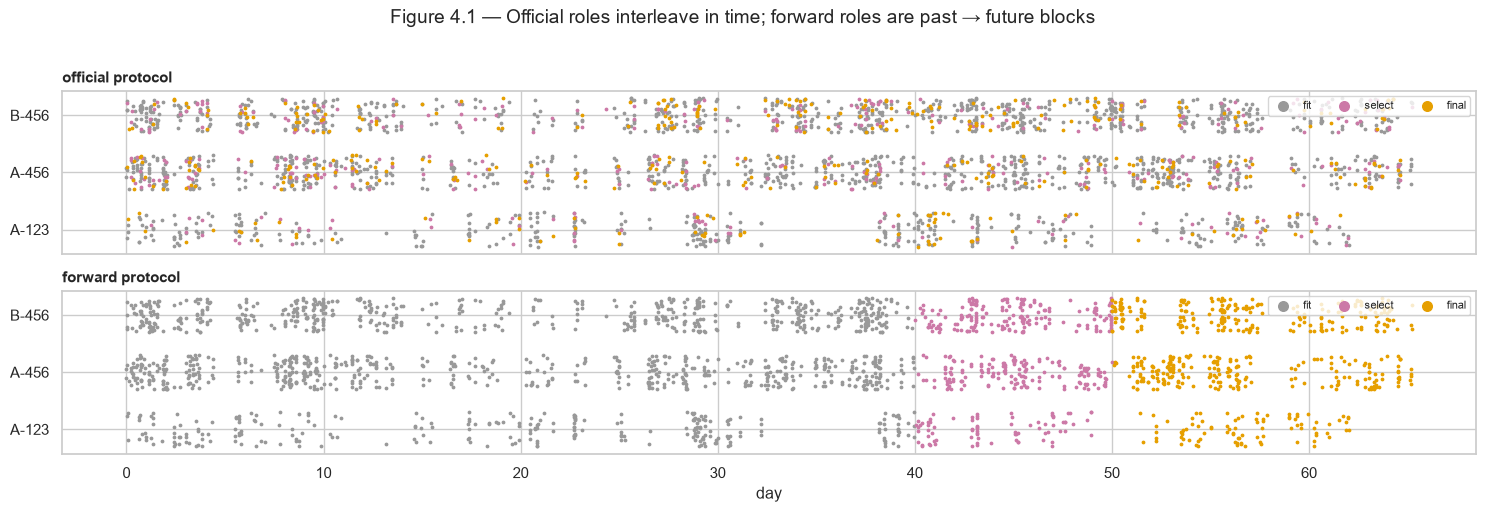

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(15, 5), sharex=True)
role_col = {'fit': '#999999', 'select': '#CC79A7', 'final': '#E69F00'}
for ax, (pname, P) in zip(axes, PROTOCOLS.items()):
    d = P['data']
    for i, m in enumerate(MODES):
        for role, c in role_col.items():
            s_ = d[(d.MODE == m) & (d.ROLE == role)]
            ax.scatter(s_.DAY, np.full(len(s_), i) + RNG.uniform(-.3, .3, len(s_)), s=3, color=c, label=role if i == 0 else None)
    ax.set_yticks(range(3)); ax.set_yticklabels(MODES); ax.set_title(f'{pname} protocol', loc='left'); ax.legend(loc='upper right', markerscale=4, ncol=3, fontsize=8)
axes[-1].set_xlabel('day')
fig.suptitle('Figure 4.1 — Official roles interleave in time; forward roles are past → future blocks', y=1.02)
fig.tight_layout(); savefig(fig, '04_01_protocols')

## 5. Baselines

Equations are only interesting relative to sensible alternatives fitted **on the same roles and the same inputs**:

| Baseline | Definition | Role in the comparison |
|---|---|---|
| Mode mean | Fitting-role mean per mode | Floor: knows only the regime |
| Preston power law | log y = log k + a·log `p_ch` + b·log `w_rot`, per mode | The textbook physical model |
| Linear | OLS on the experiment's scaled inputs, per mode | Simplest equation-like model; a "complexity" reference |
| Gradient boosting | `HistGradientBoostingRegressor` on the experiment's inputs, per mode | Black-box accuracy ceiling at equal information |

Equations, linear models and gradient boosting are all fitted **separately per mode** ("routed"), reflecting Notebook 1's finding that the modes are distinct regimes.

In [6]:
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

class Routed:
    """One sub-model per mode; predict() dispatches each row to its mode's model."""
    def __init__(self, models, kind, experiment=None, engine=None):
        self.models, self.kind, self.experiment, self.engine = models, kind, experiment, engine
    def predict(self, d):
        out = np.full(len(d), np.nan)
        for m, mdl in self.models.items():
            k = (d.MODE == m).values
            if k.any(): out[k] = mdl(d[k])
        return out

def fit_baselines(d, experiment):
    cols = [v + '_r' for v in EXPERIMENTS[experiment]]
    fit = d[d.ROLE == 'fit']
    out = {}
    out['Mode mean'] = Routed({m: (lambda q, c=fit.loc[fit.MODE == m, TARGET].mean(): np.full(len(q), c)) for m in MODES}, 'baseline')
    pres = {}
    for m in MODES:
        f = fit[fit.MODE == m]
        X = np.log(np.clip(f[['p_ch_r', 'w_rot_r']].values, 1e-6, None)); y = np.log(f[TARGET].values)
        lr = LinearRegression().fit(X, y)
        pres[m] = (lambda q, lr=lr: np.exp(lr.predict(np.log(np.clip(q[['p_ch_r', 'w_rot_r']].values, 1e-6, None)))))
    out['Preston power law'] = Routed(pres, 'baseline')
    lin, gbm = {}, {}
    for m in MODES:
        f = fit[fit.MODE == m]
        l_ = LinearRegression().fit(f[cols], f[TARGET]); lin[m] = (lambda q, l_=l_: l_.predict(q[cols]))
        g_ = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                                           l2_regularization=1.0, random_state=CONFIG['seed']).fit(f[cols], f[TARGET])
        gbm[m] = (lambda q, g_=g_: g_.predict(q[cols]))
    out['Linear'] = Routed(lin, 'baseline')
    out['Gradient boosting'] = Routed(gbm, 'baseline')
    return out

BASELINES = {(p, e): fit_baselines(P['data'], e) for p, P in PROTOCOLS.items() for e in EXPERIMENTS}
rows = []
for (p, e), models in BASELINES.items():
    sel = PROTOCOLS[p]['data'].query("ROLE == 'select'")
    for name, mdl in models.items():
        if name in ('Mode mean', 'Preston power law') and e != 'physics': continue   # identical across experiments
        rows.append({'protocol': p, 'experiment': e if name not in ('Mode mean', 'Preston power law') else '-', 'baseline': name,
                     'select RMSE': rmse(sel[TARGET], mdl.predict(sel)), 'select MAE': mean_absolute_error(sel[TARGET], mdl.predict(sel))})
baseline_select = pd.DataFrame(rows)
display(baseline_select.pivot_table(index=['baseline', 'experiment'], columns='protocol', values='select RMSE').round(3))

protocol                              forward  official
baseline          experiment                           
Gradient boosting physics               10.33     8.153
                  physics+wear          10.92     3.436
                  physics+wear+drift    6.449     3.065
Linear            physics               8.486     7.717
                  physics+wear          11.67     7.039
                  physics+wear+drift    6.696     3.438
Mode mean         -                     8.327     7.717
Preston power law -                     8.625     7.759

**Reading the baseline table** (selection role; orientation only, final numbers come in §13):
* **Preston does not beat the mode mean** under either protocol, as Notebook 1 predicted.
* **Gradient boosting with wear counters is a warning sign.** Under the official protocol its selection error drops sharply (about 3.4 vs 7.7 for the mode mean). Under the forward protocol the same model is *worse* than the mode mean (about 10.9 vs 8.3). The counters are saw-tooths with different periods, so a tree ensemble can combine their phases into a **timestamp** and interpolate the drift between interleaved training runs. That trick fails the moment it has to predict the future. Notebook 1 showed one counter acting as a clock; this shows that *combinations* of counters can too.
* **Adding the drift level** helps every model under both protocols, less so forward in time, where the drift level is stale.

## 6. Symbolic regression engines

Both engines express an equation as a plain string over the variable names, for example `79.3 - 4.1 * u_dresser`. Every prediction in this notebook is computed **from that string** by one small evaluator, never from an engine's internal model object. This guarantees that the published equation *is* the model, and that predictions need neither Julia nor PySR. For PySR, the evaluator is checked against PySR's own predictions for every equation it returns.

**Complexity** follows PySR's convention: every constant, variable and operator is one node. `a * x + b` has complexity 5.

**PySR settings.** Operators `+ − × ÷ √ x² log`, with no nesting of √/log inside √/log (keeps the expressions physically readable). Maximum size 20 nodes, squared-error loss, 64-bit precision. Search length is set by the preset; seeds are listed in the configuration.

**Sparse-library settings.** The library holds xᵢ, xᵢ², √xᵢ, log xᵢ, 1/xᵢ, xᵢ·xⱼ and xᵢ/xⱼ for the experiment's variables, keeping only terms finite on the fitting data. Forward stepwise least squares adds one term at a time, up to 6 terms; each step gives one point on the Pareto front.

In [7]:
SAFE_FUNCS = {'sqrt': np.sqrt, 'square': np.square, 'log': np.log, 'exp': np.exp, 'abs': np.abs,
              'cube': lambda v: np.power(v, 3), 'neg': np.negative}
_ALLOWED = re.compile(r'^[\w\s\.\+\-\*/\(\),eE]*$')

def eval_expr(expr, X):
    """Evaluate an equation string (PySR/Julia or sparse syntax) on a DataFrame of named variables."""
    e = expr.replace('^', '**')
    if not _ALLOWED.match(e): raise ValueError(f'unexpected characters in expression: {expr}')
    env = {**SAFE_FUNCS, **{c: X[c].to_numpy(dtype=float) for c in X.columns}}
    with np.errstate(all='ignore'):
        val = eval(e, {'__builtins__': {}}, env)
    return np.broadcast_to(np.asarray(val, dtype=float), (len(X),)).copy()

def variables_in(expr, names):
    return sorted(v for v in names if re.search(rf'\b{re.escape(v)}\b', expr))

def pretty(expr, digits=4):
    """Readable form: constants rounded; simplified with SymPy when available."""
    if SYMPY_OK:
        try:
            loc = {'square': lambda x: x ** 2, 'sqrt': sympy.sqrt, 'log': sympy.log}
            s = sympy.sympify(expr.replace('^', '**'), locals=loc)
            return str(sympy.N(sympy.simplify(s), digits)).replace('**', '^')
        except Exception:
            pass
    return re.sub(r'(?<![\w.])(\d+\.\d+(?:[eE][-+]?\d+)?)', lambda m: f'{float(m.group(1)):.{digits}g}', expr)

def xframe(d, variables):
    """Scaled inputs under their short names (the names used inside equations)."""
    return pd.DataFrame({v: d[v + '_r'].to_numpy(float) for v in variables}, index=d.index)

def data_hash(*arrays):
    h = hashlib.sha256()
    for a in arrays: h.update(np.ascontiguousarray(np.asarray(a, dtype=float)).tobytes())
    return h.hexdigest()[:16]

In [8]:
UNARY_T = [('{v}', lambda x: x, 1), ('square({v})', np.square, 2), ('sqrt({v})', np.sqrt, 2), ('log({v})', np.log, 2), ('(1 / {v})', lambda x: 1.0 / x, 3)]

def build_library(Xfit):
    terms = []
    for v in Xfit.columns:
        for fmt, _, cx in UNARY_T: terms.append((fmt.format(v=v), cx))
    for a, b in itertools.combinations(Xfit.columns, 2):
        terms += [(f'({a} * {b})', 3), (f'({a} / {b})', 3), (f'({b} / {a})', 3)]
    keep, cols = [], []
    for expr, cx in terms:
        t = eval_expr(expr, Xfit)
        if np.all(np.isfinite(t)) and np.std(t) > 1e-9:
            keep.append((expr, cx)); cols.append(t)
    return keep, np.column_stack(cols)

def sparse_sr(Xfit, y, max_terms=CONFIG['sparse_max_terms']):
    """Forward stepwise selection over the term library -> list of (complexity, equation string)."""
    lib, T = build_library(Xfit)
    y = np.asarray(y, float); n = len(y)
    sel, front = [], [(1, repr(float(y.mean())))]
    for _ in range(max_terms):
        best = None
        for j in range(T.shape[1]):
            if j in sel: continue
            A = np.column_stack([np.ones(n), T[:, sel + [j]]])
            coef, _, rank, _ = np.linalg.lstsq(A, y, rcond=None)
            if rank < A.shape[1]: continue
            r = np.sum((y - A @ coef) ** 2)
            if best is None or r < best[0]: best = (r, j, coef)
        if best is None: break
        sel.append(best[1]); coef = best[2]
        expr = repr(float(coef[0])) + ''.join(f' + ({float(c)!r} * {lib[j][0]})' for c, j in zip(coef[1:], sel))
        cx = 1 + sum(lib[j][1] + 3 for j in sel)
        front.append((cx, expr))
    return pd.DataFrame(front, columns=['complexity', 'equation'])

def run_pysr(Xfit, y, seed):
    """One PySR search; returns its Pareto front (complexity, loss, equation) with an export check."""
    nested = {'sqrt': {'sqrt': 0, 'log': 0}, 'log': {'sqrt': 0, 'log': 0}, 'square': {'square': 0}}
    kw = dict(niterations=CONFIG['niterations'], binary_operators=CONFIG['binary_operators'], unary_operators=CONFIG['unary_operators'],
              nested_constraints=nested, maxsize=CONFIG['maxsize'], populations=CONFIG['populations'], population_size=CONFIG['population_size'],
              model_selection='best', elementwise_loss='L2DistLoss()', precision=64, random_state=seed,
              deterministic=REPRODUCIBLE_PYSR, parallelism='serial' if REPRODUCIBLE_PYSR else 'multithreading',
              progress=False, verbosity=0, output_directory=str(CACHE / 'pysr_runs'))   # PySR forbids temp_equation_file together with output_directory
    allowed = set(inspect.signature(PySRRegressor.__init__).parameters)
    model = PySRRegressor(**{k: v for k, v in kw.items() if k in allowed})
    model.fit(Xfit, np.asarray(y, float))
    eqs = model.equations_[['complexity', 'loss', 'equation']].reset_index(drop=True).copy()
    ok = []
    for i in range(len(eqs)):
        try:
            ours, theirs = eval_expr(eqs.equation[i], Xfit), np.asarray(model.predict(Xfit, index=i), float)
            ok.append(bool(np.allclose(ours, theirs, rtol=1e-6, atol=1e-6, equal_nan=True)))
        except Exception:
            ok.append(False)
    eqs['export_verified'] = ok
    return eqs

## 7. Running the searches

One search runs per **protocol × experiment × mode × engine**, and for PySR per seed as well. Every experiment gets the same search budget. Results are cached under a key that includes the configuration *and* a hash of the fitting data: changing either triggers a fresh search, and nothing stale is reused.

In [9]:
jobs = [(p, e, m) for p in PROTOCOLS for e in EXPERIMENTS for m in MODES]
n_pysr = len(jobs) * len(CONFIG['seeds']) if PYSR_OK else 0
print(f'{len(jobs)} sparse searches + {n_pysr} PySR searches')
cfg_key = hashlib.sha256(json.dumps({k: CONFIG[k] for k in ['niterations', 'populations', 'population_size', 'maxsize', 'binary_operators',
                                                         'unary_operators', 'sparse_max_terms']}, sort_keys=True).encode()).hexdigest()[:10]
candidates, timings, done_pysr = [], [], 0
t_start = time.time()
for p, e, m in jobs:
    d = PROTOCOLS[p]['data']; fit = d[(d.ROLE == 'fit') & (d.MODE == m)]
    Xf, yf = xframe(fit, EXPERIMENTS[e]), fit[TARGET].values
    dh = data_hash(Xf.values, yf)
    runs_ = [('Sparse', None)] + ([('PySR', s) for s in CONFIG['seeds']] if PYSR_OK else [])
    for engine, seed in runs_:
        key = f'{engine}_{p}_{e}_{m}_{seed}_{cfg_key}_{dh}'.replace('+', 'p')
        path = CACHE / f'{key}.csv'
        if path.exists():
            front = pd.read_csv(path)
        else:
            t0 = time.time()
            front = sparse_sr(Xf, yf) if engine == 'Sparse' else run_pysr(Xf, yf, seed)
            front.to_csv(path, index=False)
            if engine == 'PySR':
                timings.append(time.time() - t0); done_pysr += 1
                remaining = n_pysr - sum(1 for _ in CACHE.glob(f'PySR_*_{cfg_key}_*.csv'))
                print(f'  PySR {p}/{e}/{m}/seed {seed}: {timings[-1]:.0f} s | about {remaining * np.mean(timings) / 60:.0f} min of searches left', flush=True)
        front = front.assign(protocol=p, experiment=e, mode=m, engine=engine, seed=seed)
        candidates.append(front)
cand = pd.concat(candidates, ignore_index=True)
if timings: print(f'PySR: {len(timings)} new searches, mean {np.mean(timings):.0f} s each')
print(f'Searches complete in {time.time() - t_start:.0f} s | {len(cand):,} candidate equations on the Pareto fronts')
if 'export_verified' in cand:
    v = cand.loc[cand.engine == 'PySR', 'export_verified']
    print(f'PySR equations whose exported string reproduces PySR predictions: {v.mean():.1%} of {len(v)}')

18 sparse searches + 36 PySR searches


c:\Users\Ekta Jain\ml-env\Lib\site-packages\pysr\sr.py:2409: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


  PySR official/physics/A-123/seed 11: 121 s | about 71 min of searches left


c:\Users\Ekta Jain\ml-env\Lib\site-packages\pysr\sr.py:2409: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


  PySR official/physics/A-123/seed 22: 10 s | about 37 min of searches left


...

  PySR forward/physics+wear+drift/A-456/seed 22: 10 s | about 1 min of searches left


c:\Users\Ekta Jain\ml-env\Lib\site-packages\pysr\sr.py:2409: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


  PySR forward/physics+wear+drift/B-456/seed 11: 9 s | about 0 min of searches left


c:\Users\Ekta Jain\ml-env\Lib\site-packages\pysr\sr.py:2409: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


  PySR forward/physics+wear+drift/B-456/seed 22: 12 s | about 0 min of searches left
PySR: 36 new searches, mean 16 s each
Searches complete in 590 s | 622 candidate equations on the Pareto fronts
PySR equations whose exported string reproduces PySR predictions: 100.0% of 496


## 8. Pareto fronts and model selection

**Selection rule (fixed before any results were seen).** For each protocol × experiment × mode × engine, all Pareto-front equations from all seeds are scored on the **select** role. Let *best* be the lowest selection RMSE. The chosen equation is the **simplest** one whose selection RMSE is within 5% of *best*; ties go to the lower RMSE. This rule prefers short equations whenever extra complexity buys little, and it never looks at the final role.

In [10]:
def score(row):
    d = PROTOCOLS[row.protocol]['data']
    rows_ = {}
    for role in ['fit', 'select']:
        q = d[(d.ROLE == role) & (d.MODE == row['mode'])]
        try: p_ = eval_expr(row.equation, xframe(q, EXPERIMENTS[row.experiment]))
        except Exception: p_ = np.full(len(q), np.nan)
        rows_[f'{role}_rmse'] = rmse(q[TARGET], p_) if np.all(np.isfinite(p_)) else np.inf
    return pd.Series(rows_)

cand[['fit_rmse', 'select_rmse']] = cand.apply(score, axis=1)
cand['variables'] = [', '.join(variables_in(eq, EXPERIMENTS[e])) for eq, e in zip(cand.equation, cand.experiment)]

def choose(g, tol=CONFIG['selection_tolerance']):
    g = g[np.isfinite(g.select_rmse)]
    best = g.select_rmse.min()
    ok = g[g.select_rmse <= best * (1 + tol)]
    return ok.sort_values(['complexity', 'select_rmse']).iloc[0]

chosen = pd.DataFrame([choose(g) for _, g in cand.groupby(['protocol', 'experiment', 'mode', 'engine'], sort=True)]).reset_index(drop=True)
chosen['pretty'] = chosen.equation.map(pretty)
display(chosen[['protocol', 'experiment', 'mode', 'engine', 'complexity', 'fit_rmse', 'select_rmse', 'variables', 'pretty']])

,protocol,experiment,mode,engine,complexity,fit_rmse,select_rmse,variables,pretty
0,forward,physics,A-123,PySR,1,3.3,6.044,,150.0
1,forward,physics,A-123,Sparse,1,3.3,6.044,,150.0
2,forward,physics,A-456,PySR,1,7.1,7.759,,70.89
3,forward,physics,A-456,Sparse,1,7.1,7.759,,70.89
4,forward,physics,B-456,PySR,1,9.301,9.566,,76.46
5,forward,physics,B-456,Sparse,1,9.301,9.566,,76.46
6,forward,physics+wear,A-123,PySR,8,2.787,5.065,"u_dresser, u_film",-u_dresser^2*(u_film - 1.935)^2 + 151.5
7,forward,physics+wear,A-123,Sparse,12,2.908,5.674,"u_dresser, u_film",-2.166*u_dresser^2 + 1.277*u_dresser*u_film + ...
8,forward,physics+wear,A-456,PySR,12,4.621,5.312,"u_dresser, u_film",(u_film + (76.78 - 3.48*u_dresser^2)*(u_dresse...
9,forward,physics+wear,A-456,Sparse,1,7.1,7.759,,70.89


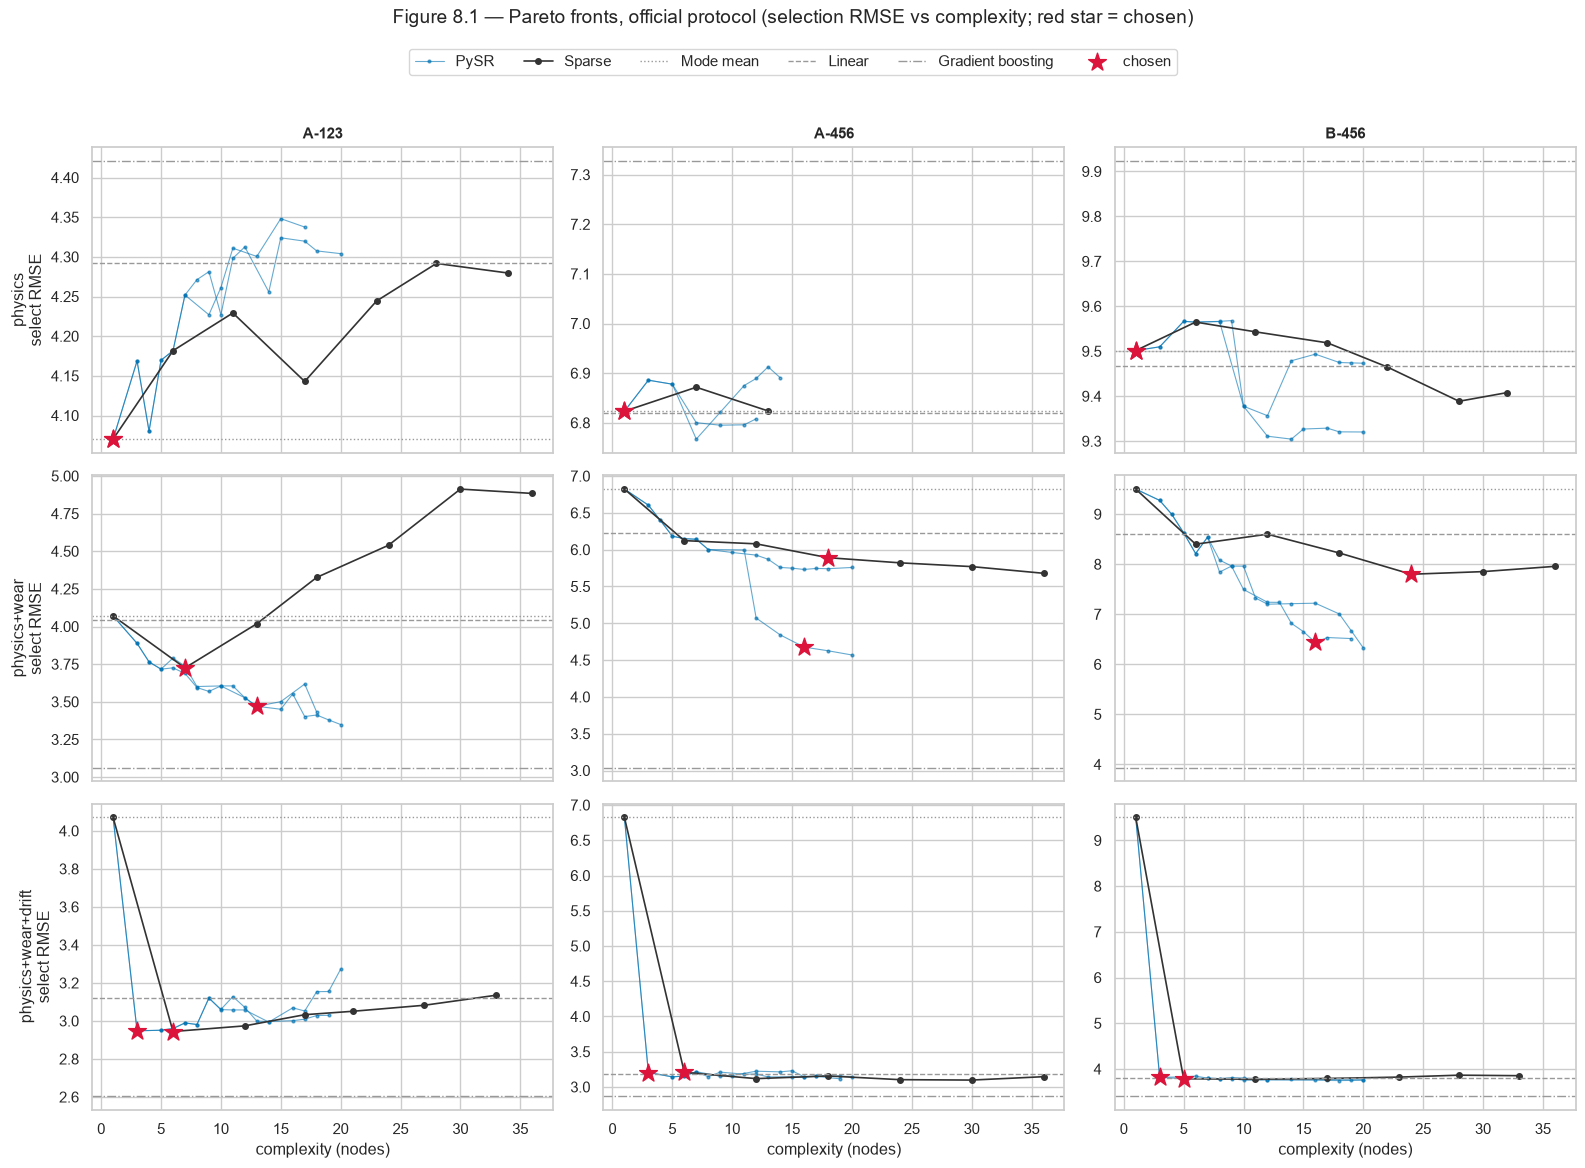

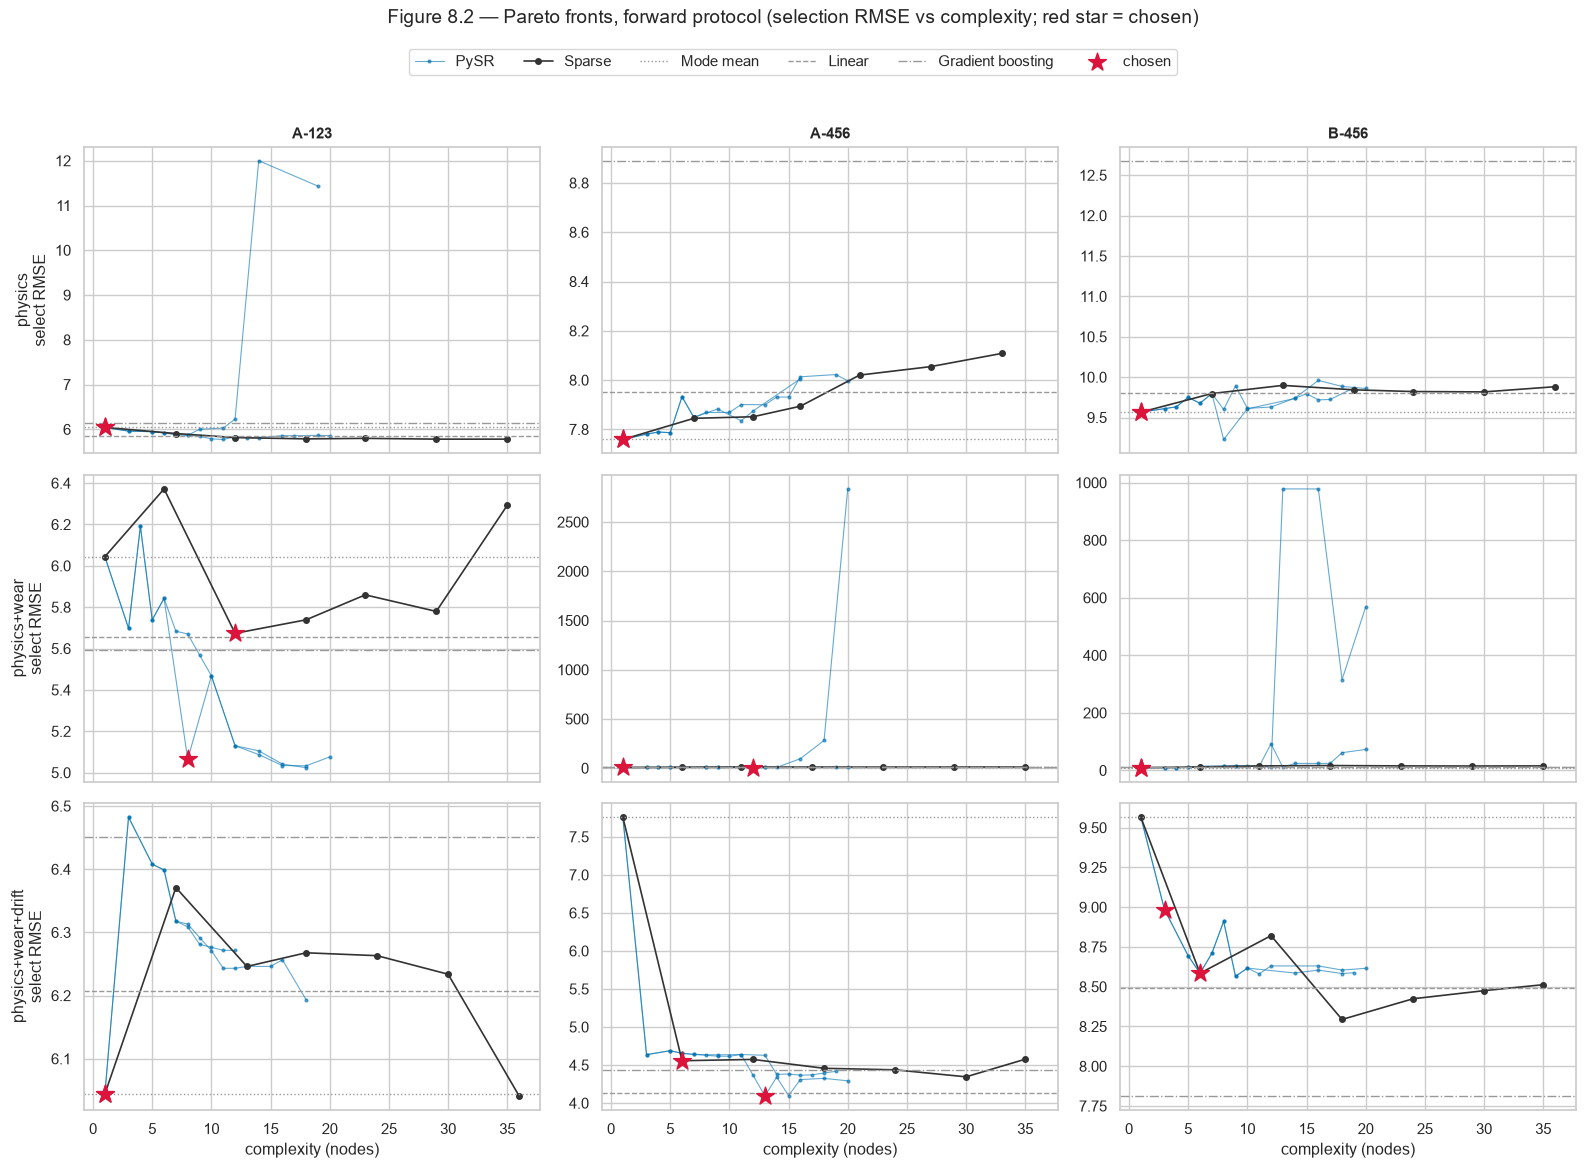

In [11]:
for p in PROTOCOLS:
    fig, axes = plt.subplots(len(EXPERIMENTS), len(MODES), figsize=(16, 11), sharex=True)
    for i, e in enumerate(EXPERIMENTS):
        for j, m in enumerate(MODES):
            ax = axes[i, j]
            c = cand[(cand.protocol == p) & (cand.experiment == e) & (cand['mode'] == m) & np.isfinite(cand.select_rmse)]
            for (eng, seed), g in c.groupby(['engine', c.seed.fillna(-1)]):
                g = g.sort_values('complexity')
                ax.plot(g.complexity, g.select_rmse, 'o-' if eng == 'Sparse' else '.-', ms=4, lw=1.2 if eng == 'Sparse' else .8,
                        alpha=1 if eng == 'Sparse' else .6, color='#333' if eng == 'Sparse' else '#0072B2',
                        label=eng if (seed in (-1, CONFIG['seeds'][0])) else None)
            sel = PROTOCOLS[p]['data'].query("ROLE == 'select'"); sel = sel[sel.MODE == m]
            for bname, ls in [('Mode mean', ':'), ('Linear', '--'), ('Gradient boosting', '-.')]:
                ax.axhline(rmse(sel[TARGET], BASELINES[(p, e)][bname].predict(sel)), color='#999', ls=ls, lw=1, label=bname)
            ch = chosen[(chosen.protocol == p) & (chosen.experiment == e) & (chosen['mode'] == m)]
            ax.scatter(ch.complexity, ch.select_rmse, marker='*', s=180, color='crimson', zorder=5, label='chosen')
            if i == 0: ax.set_title(m)
            if j == 0: ax.set_ylabel(f'{e}\nselect RMSE')
            if i == len(EXPERIMENTS) - 1: ax.set_xlabel('complexity (nodes)')
    h, l = axes[0, 0].get_legend_handles_labels(); uniq = dict(zip(l, h))
    fig.legend(uniq.values(), uniq.keys(), loc='upper center', ncol=7, bbox_to_anchor=(.5, 1.03))
    fig.suptitle(f'Figure 8.{1 if p == "official" else 2} — Pareto fronts, {p} protocol (selection RMSE vs complexity; red star = chosen)', y=1.06)
    fig.tight_layout(); savefig(fig, f'08_pareto_{p}')

**Reading the Pareto fronts.** Each curve shows how selection error falls as equations grow. Where a curve flattens early, extra complexity buys nothing, and the selection rule picks a short equation. Grey reference lines mark the baselines on the same inputs: an equation below the dotted line beats "regime only", and one near the dash-dot line matches gradient boosting.

## 9. The selected equations

The equations below use the **scaled** variables: each variable divided by its fitting-data median for that mode, so 1.0 means typical. The second table gives those medians, so any equation can be written in raw units by substitution.

In [12]:
for p in PROTOCOLS:
    display(Markdown(f'**{p} protocol**'))
    for e in EXPERIMENTS:
        lines = []
        for eng in ENGINES:
            for m in MODES:
                r = chosen[(chosen.protocol == p) & (chosen.experiment == e) & (chosen['mode'] == m) & (chosen.engine == eng)]
                if len(r): lines.append(f'| {e} | {eng} | {m} | {int(r.complexity.iloc[0])} | {r.select_rmse.iloc[0]:.3f} | `MRR = {r.pretty.iloc[0]}` |')
        display(Markdown('| experiment | engine | mode | complexity | select RMSE | equation |\n|---|---|---|---|---|---|\n' + '\n'.join(lines)))
print('Scaling medians (fitting role, official protocol): x_scaled = x_raw / median')
display(PROTOCOLS['official']['scale'].round(4))

**official protocol**

| experiment | engine | mode | complexity | select RMSE | equation |
|---|---|---|---|---|---|
| physics | PySR | A-123 | 1 | 4.070 | `MRR = 151.2` |
| physics | PySR | A-456 | 1 | 6.823 | `MRR = 73.08` |
| physics | PySR | B-456 | 1 | 9.502 | `MRR = 79.97` |
| physics | Sparse | A-123 | 1 | 4.070 | `MRR = 151.2` |
| physics | Sparse | A-456 | 1 | 6.823 | `MRR = 73.08` |
| physics | Sparse | B-456 | 1 | 9.502 | `MRR = 79.97` |

| experiment | engine | mode | complexity | select RMSE | equation |
|---|---|---|---|---|---|
| physics+wear | PySR | A-123 | 13 | 3.470 | `MRR = -3.626*u_dresser*(u_dresser - u_film)^2 + u_film^2 + 151.3` |
| physics+wear | PySR | A-456 | 16 | 4.677 | `MRR = -u_dresser/(0.1403 + 0.01259/(u_dresser - u_film)^3) + 76.9` |
| physics+wear | PySR | B-456 | 16 | 6.437 | `MRR = -u_dresser^2*(u_dresser - u_film)^2*(u_film*(u_film + 0.9735) + 1.0)^2 + 83.78` |
| physics+wear | Sparse | A-123 | 7 | 3.725 | `MRR = 2.789*u_film*w_rot + 148.4` |
| physics+wear | Sparse | A-456 | 18 | 5.892 | `MRR = -4.392*u_dresser^2 + 3.759*u_dresser*u_film - 3.195*u_film/w_rot + 78.39` |
| physics+wear | Sparse | B-456 | 24 | 7.800 | `MRR = -7.508*u_dresser^2 + 8.984*u_dresser*u_film - 8.74*u_film*w_rot + 87.85 + 0.8464*w_rot/u_table` |

| experiment | engine | mode | complexity | select RMSE | equation |
|---|---|---|---|---|---|
| physics+wear+drift | PySR | A-123 | 3 | 2.948 | `MRR = 151.5*drift` |
| physics+wear+drift | PySR | A-456 | 3 | 3.205 | `MRR = 74.43*drift` |
| physics+wear+drift | PySR | B-456 | 3 | 3.818 | `MRR = 82.46*drift` |
| physics+wear+drift | Sparse | A-123 | 6 | 2.945 | `MRR = 73.65*drift^2 + 77.78` |
| physics+wear+drift | Sparse | A-456 | 6 | 3.207 | `MRR = 141.7*drift^0.5 - 67.21` |
| physics+wear+drift | Sparse | B-456 | 5 | 3.787 | `MRR = 80.27*drift + 2.144` |

**forward protocol**

| experiment | engine | mode | complexity | select RMSE | equation |
|---|---|---|---|---|---|
| physics | PySR | A-123 | 1 | 6.044 | `MRR = 150.0` |
| physics | PySR | A-456 | 1 | 7.759 | `MRR = 70.89` |
| physics | PySR | B-456 | 1 | 9.566 | `MRR = 76.46` |
| physics | Sparse | A-123 | 1 | 6.044 | `MRR = 150.0` |
| physics | Sparse | A-456 | 1 | 7.759 | `MRR = 70.89` |
| physics | Sparse | B-456 | 1 | 9.566 | `MRR = 76.46` |

| experiment | engine | mode | complexity | select RMSE | equation |
|---|---|---|---|---|---|
| physics+wear | PySR | A-123 | 8 | 5.065 | `MRR = -u_dresser^2*(u_film - 1.935)^2 + 151.5` |
| physics+wear | PySR | A-456 | 12 | 5.312 | `MRR = (u_film + (76.78 - 3.48*u_dresser^2)*(u_dresser - u_film))/(u_dresser - u_film)` |
| physics+wear | PySR | B-456 | 1 | 9.566 | `MRR = 76.46` |
| physics+wear | Sparse | A-123 | 12 | 5.674 | `MRR = -2.166*u_dresser^2 + 1.277*u_dresser*u_film + 151.1` |
| physics+wear | Sparse | A-456 | 1 | 7.759 | `MRR = 70.89` |
| physics+wear | Sparse | B-456 | 1 | 9.566 | `MRR = 76.46` |

| experiment | engine | mode | complexity | select RMSE | equation |
|---|---|---|---|---|---|
| physics+wear+drift | PySR | A-123 | 1 | 6.044 | `MRR = 150.0` |
| physics+wear+drift | PySR | A-456 | 13 | 4.094 | `MRR = 65.86*drift + q_slurry - u_dresser + 5.542 + 0.2237/u_table` |
| physics+wear+drift | PySR | B-456 | 3 | 8.985 | `MRR = 77.01*drift` |
| physics+wear+drift | Sparse | A-123 | 1 | 6.044 | `MRR = 150.0` |
| physics+wear+drift | Sparse | A-456 | 6 | 4.557 | `MRR = 69.1*log(drift) + 71.91` |
| physics+wear+drift | Sparse | B-456 | 6 | 8.585 | `MRR = 143.5*drift^0.5 - 66.22` |

Scaling medians (fitting role, official protocol): x_scaled = x_raw / median


,p_ch,p_ring,w_rot,q_slurry,t_act,u_dresser,u_film,u_table,drift
MODE,,,,,,,,,
A-123,62.21,"1,449",32.16,272,82,481.9,"5,231",143.7,151.5
A-456,74.64,"1,513",32.86,421.1,152.3,385.2,"4,742",157.4,74.25
B-456,71.45,"1,525",32.88,423.6,152,390,"5,383",179.3,82.25


## 10. Stability: are the same equations rediscovered?

One equation from one search proves little: a different seed or slightly different data could produce a different formula. Two checks:
* **Across PySR seeds:** apply the selection rule to each seed separately and record which variables the chosen equation uses.
* **Wafer bootstrap (sparse engine):** resample the fitting runs by wafer *B* times, rerun the search and selection each time, and record how often each variable is chosen. A variable that appears in, say, 90% of resamples is a stable finding; one at 20% is noise.

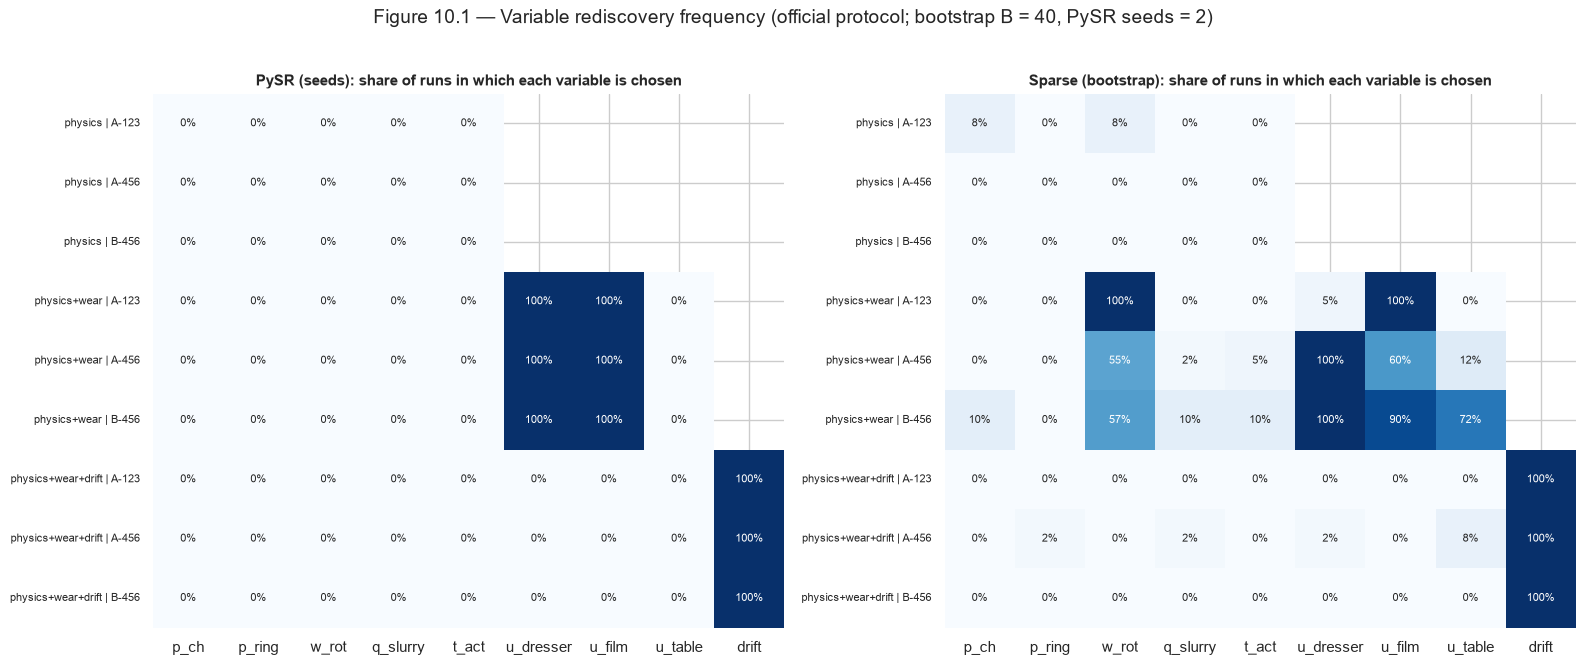

median  min  max
engine             experiment         mode                   
PySR (seeds)       physics            A-123       1    1    1
                                      A-456       1    1    1
                                      B-456       1    1    1
                   physics+wear       A-123    10.5    8   13
                                      A-456      12    8   16
                                      B-456    17.5   15   20
                   physics+wear+drift A-123       3    3    3
                                      A-456       3    3    3
                                      B-456       3    3    3
Sparse (bootstrap) physics            A-123       1    1    7
                                      A-456       1    1    1
                                      B-456       1    1    1
                   physics+wear       A-123       7    7   13
                                      A-456      17    5   25
                                      B-456      23    6   36
                   physics+wear+drift A-123       6    6    6
                                      A-456       6    5   12
                                      B-456       5    5    6

In [13]:
stab_rows = []
B = CONFIG['bootstraps']
for e in EXPERIMENTS:
    for m in MODES:
        d = PROTOCOLS['official']['data']
        fit = d[(d.ROLE == 'fit') & (d.MODE == m)]; sel = d[(d.ROLE == 'select') & (d.MODE == m)]
        wafers = fit.WAFER_ID.unique(); rng_b = np.random.default_rng(CONFIG['seed'] + 100 * list(EXPERIMENTS).index(e) + MODES.index(m))
        Xs = xframe(sel, EXPERIMENTS[e])
        for b in range(B):
            pick = rng_b.choice(wafers, size=len(wafers), replace=True)
            fb = pd.concat([fit[fit.WAFER_ID == w] for w in pick], ignore_index=True)
            front = sparse_sr(xframe(fb, EXPERIMENTS[e]), fb[TARGET].values)
            front['select_rmse'] = [rmse(sel[TARGET], eval_expr(eq, Xs)) if np.all(np.isfinite(eval_expr(eq, Xs))) else np.inf for eq in front.equation]
            front = front.assign(protocol='official', experiment=e, mode=m)
            ch = choose(front)
            used = variables_in(ch.equation, EXPERIMENTS[e])
            stab_rows.append({'experiment': e, 'mode': m, 'engine': 'Sparse (bootstrap)', 'rep': b, 'complexity': ch.complexity,
                              **{v: v in used for v in EXPERIMENTS['physics+wear+drift']}})
        if PYSR_OK:
            for s in CONFIG['seeds']:
                g = cand[(cand.protocol == 'official') & (cand.experiment == e) & (cand['mode'] == m) & (cand.engine == 'PySR') & (cand.seed == s)]
                if len(g):
                    ch = choose(g); used = variables_in(ch.equation, EXPERIMENTS[e])
                    stab_rows.append({'experiment': e, 'mode': m, 'engine': 'PySR (seeds)', 'rep': s, 'complexity': ch.complexity,
                                      **{v: v in used for v in EXPERIMENTS['physics+wear+drift']}})
stab = pd.DataFrame(stab_rows)
allv = EXPERIMENTS['physics+wear+drift']
freq = stab.groupby(['engine', 'experiment', 'mode'])[allv].mean()
for v_ in allv:   # variables not offered in an experiment are shown as blank, not 0
    for e in EXPERIMENTS:
        if v_ not in EXPERIMENTS[e]: freq.loc[(slice(None), e, slice(None)), v_] = np.nan
stab.to_csv(SR / 'stability_selections.csv', index=False)

fig, axes = plt.subplots(1, len(freq.index.get_level_values(0).unique()), figsize=(16, 6.5), squeeze=False)
for ax, eng in zip(axes[0], freq.index.get_level_values(0).unique()):
    f_ = freq.loc[eng]; f_.index = [f'{e} | {m}' for e, m in f_.index]
    sns.heatmap(f_, ax=ax, vmin=0, vmax=1, cmap='Blues', annot=True, fmt='.0%', annot_kws={'size': 8}, cbar=False, mask=f_.isna())
    ax.set_title(f'{eng}: share of runs in which each variable is chosen'); ax.tick_params(axis='y', labelsize=8)
fig.suptitle(f'Figure 10.1 — Variable rediscovery frequency (official protocol; bootstrap B = {B}, PySR seeds = {len(CONFIG["seeds"]) if PYSR_OK else 0})', y=1.02)
fig.tight_layout(); savefig(fig, '10_01_stability')
cx_spread = stab.groupby(['engine', 'experiment', 'mode']).complexity.agg(['median', 'min', 'max'])
display(cx_spread)

**Reading Figure 10.1.** Dark cells are variables the search keeps coming back to. Light cells are variables it picks up only occasionally, and those should not be interpreted even if they appear in the single chosen equation of §9. The complexity range shows how much the chosen size moves between resamples.

Note that `w_rot` is essentially constant (≈ 1.0 after scaling, CV ≈ 2%). When it appears in a product such as `w_rot * u_film`, the term behaves like the other variable alone, so its selection frequency says little about wafer rotation itself.

## 11. Physical plausibility and behaviour of the equations

An equation can fit well and still be physically odd. Each chosen equation is checked in three ways:
1. **Signs.** The local slope of predicted MRR with respect to each variable, evaluated at every selection-role run. Preston expects pressure ≥ 0; Notebook 1 found dresser wear < 0.
2. **Domain safety.** Are predictions finite for every run, including rows whose labels are still sealed? And under extrapolation: each variable pushed from 0.5× its smallest to 1.5× its largest fitted value, with the others held at typical (1.0)?
3. **Partial dependence.** The equation's curve for each variable, others at typical values, drawn over the binned data.

In [14]:
def slopes(expr, X, v, h=1e-4):
    Xp, Xm = X.copy(), X.copy(); Xp[v] = Xp[v] * (1 + h); Xm[v] = Xm[v] * (1 - h)
    return (eval_expr(expr, Xp) - eval_expr(expr, Xm)) / (2 * h * X[v].values)

plaus = []
for _, r in chosen.iterrows():
    d = PROTOCOLS[r.protocol]['data']; q = d[d.MODE == r['mode']]
    X = xframe(q, EXPERIMENTS[r.experiment]); Xs = X[(q.ROLE == 'select').values]
    pred_all = eval_expr(r.equation, X)
    fit_x = X[(q.ROLE == 'fit').values]
    stress_ok = True
    for v in X.columns:
        grid = pd.DataFrame({c: np.ones(200) for c in X.columns}); grid[v] = np.linspace(.5 * fit_x[v].min(), 1.5 * fit_x[v].max(), 200)
        stress_ok &= bool(np.all(np.isfinite(eval_expr(r.equation, grid))))
    row = {'protocol': r.protocol, 'experiment': r.experiment, 'mode': r['mode'], 'engine': r.engine,
           'finite on all runs': bool(np.all(np.isfinite(pred_all))), 'finite under stress': stress_ok}
    for v in variables_in(r.equation, EXPERIMENTS[r.experiment]):
        s_ = slopes(r.equation, Xs, v)
        row[f'slope {v}'] = f"{np.median(s_):+.2f} ({np.mean(np.sign(s_) == np.sign(np.median(s_))):.0%} same sign)"
    plaus.append(row)
plaus = pd.DataFrame(plaus)
display(plaus[plaus.protocol == 'official'].drop(columns='protocol').fillna(''))

C:\Users\Ekta Jain\AppData\Local\Temp\ipykernel_24572\2107617556.py:3: RuntimeWarning: invalid value encountered in divide
  return (eval_expr(expr, Xp) - eval_expr(expr, Xm)) / (2 * h * X[v].values)


,experiment,mode,engine,finite on all runs,finite under stress,slope u_dresser,slope u_film,slope drift,slope q_slurry,slope u_table,slope w_rot
18,physics,A-123,PySR,True,True,,,,,,
19,physics,A-123,Sparse,True,True,,,,,,
20,physics,A-456,PySR,True,True,,,,,,
21,physics,A-456,Sparse,True,True,,,,,,
22,physics,B-456,PySR,True,True,,,,,,
23,physics,B-456,Sparse,True,True,,,,,,
24,physics+wear,A-123,PySR,True,True,-1.03 (69% same sign),+1.07 (93% same sign),,,,
25,physics+wear,A-123,Sparse,True,True,,+2.79 (100% same sign),,,,+2.79 (100% same sign)
26,physics+wear,A-456,PySR,True,True,-9.17 (100% same sign),+1.84 (100% same sign),,,,
27,physics+wear,A-456,Sparse,True,True,-5.14 (73% same sign),+0.47 (58% same sign),,,,+3.44 (100% same sign)


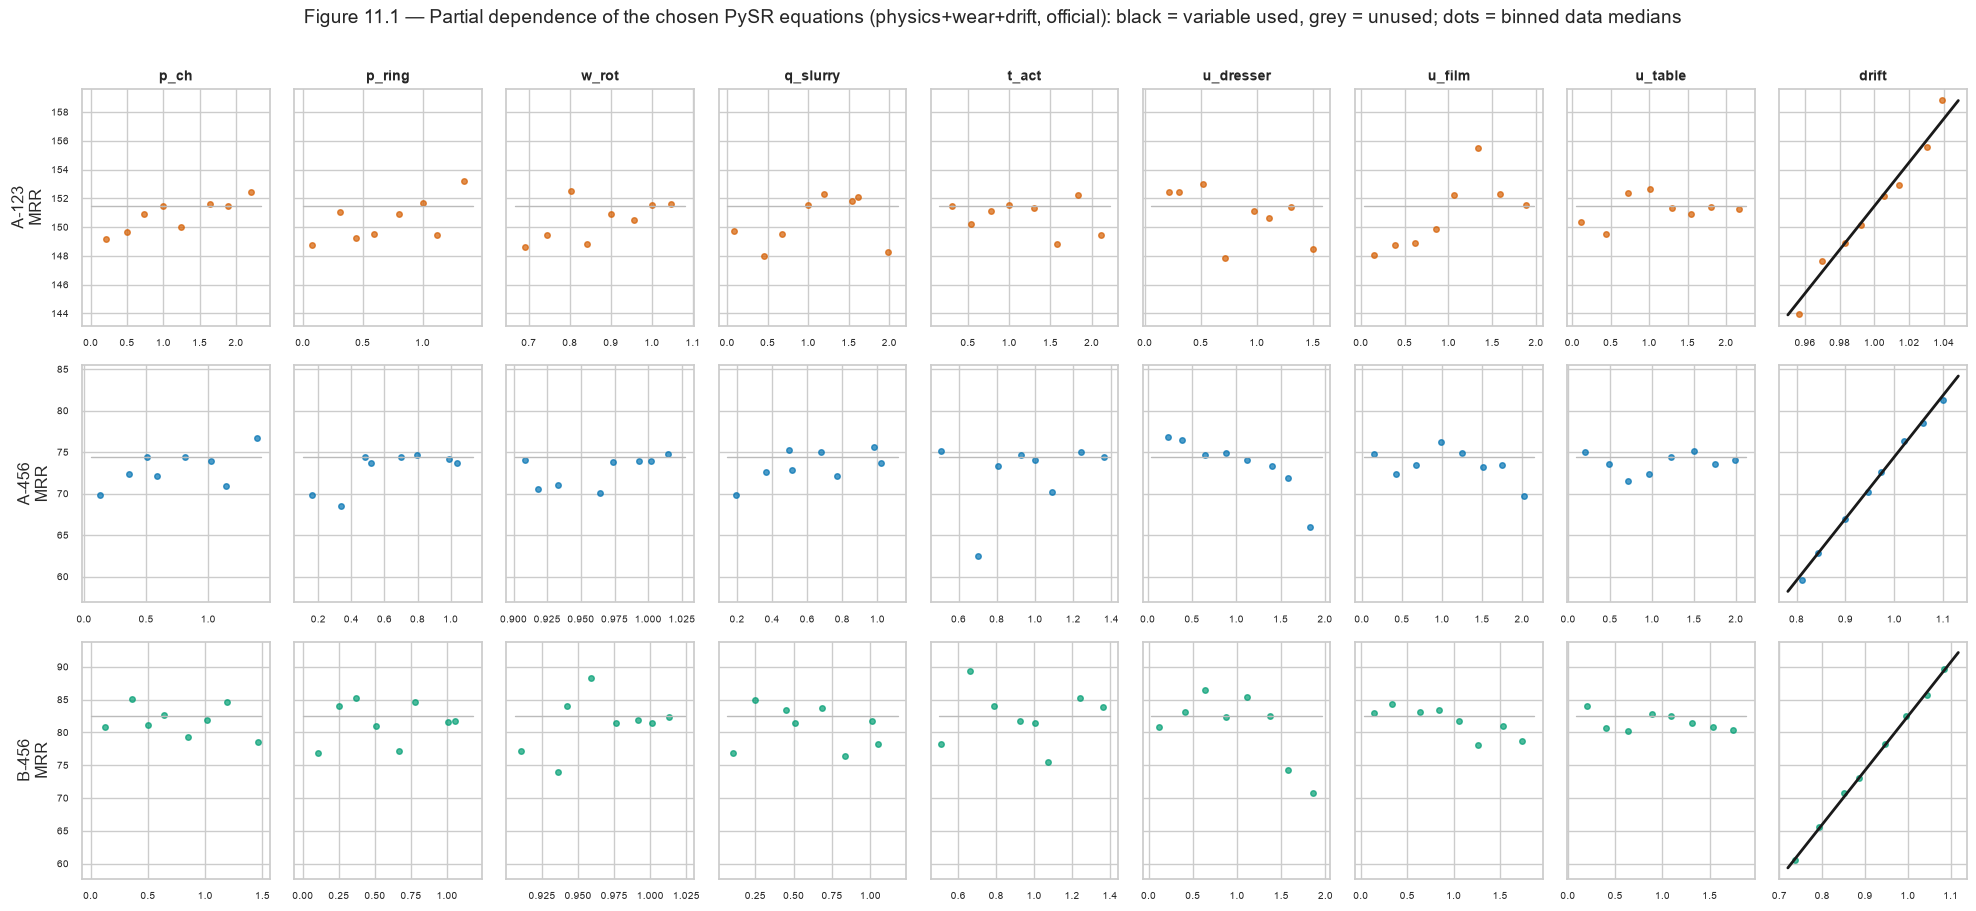

In [15]:
MAIN_EXP = 'physics+wear+drift'
main_engine = ENGINES[0]
fig, axes = plt.subplots(len(MODES), len(EXPERIMENTS[MAIN_EXP]), figsize=(20, 9), sharey='row')
d = PROTOCOLS['official']['data']
for i, m in enumerate(MODES):
    r = chosen[(chosen.protocol == 'official') & (chosen.experiment == MAIN_EXP) & (chosen['mode'] == m) & (chosen.engine == main_engine)].iloc[0]
    q = d[(d.MODE == m) & d.ROLE.isin(['fit', 'select'])]
    X = xframe(q, EXPERIMENTS[MAIN_EXP])
    for j, v in enumerate(EXPERIMENTS[MAIN_EXP]):
        ax = axes[i, j]
        lo, hi = X[v].quantile(.01), X[v].quantile(.99)
        if hi <= lo: lo, hi = lo * .9, hi * 1.1
        bins = pd.cut(X[v], np.linspace(lo, hi, 9))
        med_y = q[TARGET].groupby(bins, observed=True).median(); mid = X[v].groupby(bins, observed=True).median()
        ax.plot(mid, med_y, 'o', color=MODE_COLORS[m], ms=4, alpha=.7)
        grid = pd.DataFrame({c: np.ones(100) for c in X.columns}); grid[v] = np.linspace(lo, hi, 100)
        used = v in variables_in(r.equation, EXPERIMENTS[MAIN_EXP])
        ax.plot(grid[v], eval_expr(r.equation, grid), color='k' if used else '#bbb', lw=2 if used else 1)
        if i == 0: ax.set_title(v, fontsize=10)
        if j == 0: ax.set_ylabel(f'{m}\nMRR')
        ax.tick_params(labelsize=7)
fig.suptitle(f'Figure 11.1 — Partial dependence of the chosen {main_engine} equations ({MAIN_EXP}, official): black = variable used, grey = unused; dots = binned data medians', y=1.01)
fig.tight_layout(); savefig(fig, '11_01_partial_dependence')

**How to read Figure 11.1.** For variables the equation uses (black), the curve's slope is its claimed effect when everything else is typical. The dots are *raw* binned medians, which mix in the effects of other variables, so the curve and the dots need not coincide. What matters is the direction and size of the effect, and whether the curve behaves sensibly at the edges.

## 12. Freezing the models

Every chosen equation, plus the baseline definitions and the scaling constants, is written to `outputs/sr/frozen_models.json` together with a SHA-256 fingerprint. Only then are the official test labels read. Nothing after this point changes a model.

In [16]:
frozen = {'created': time.strftime('%Y-%m-%d %H:%M:%S'), 'config': CONFIG, 'engines': ENGINES, 'pysr_status': PYSR_MSG,
          'equations': chosen[['protocol', 'experiment', 'mode', 'engine', 'complexity', 'equation', 'select_rmse']].to_dict('records'),
          'scaling_medians': {p: P['scale'].to_dict() for p, P in PROTOCOLS.items()}, 'experiments': EXPERIMENTS, 'variables': VARS}
blob = json.dumps(frozen, sort_keys=True, default=float).encode()
frozen['sha256'] = hashlib.sha256(blob).hexdigest()
(SR / 'frozen_models.json').write_text(json.dumps(frozen, indent=1, default=float), encoding='utf-8')
print('Frozen', len(chosen), 'equations | fingerprint', frozen['sha256'][:16])

SR_MODELS = {}
for (p, e, eng), g in chosen.groupby(['protocol', 'experiment', 'engine']):
    SR_MODELS[(p, e, eng)] = Routed({r['mode']: (lambda q, ex=r.equation, vs=EXPERIMENTS[e]: eval_expr(ex, xframe(q, vs))) for _, r in g.iterrows()},
                                    'sr', e, eng)

Frozen 36 equations | fingerprint e2aa76f012a7b8e2


## 13. Final evaluation on held-out data (opened once)

*Official protocol:* the sealed test labels are loaded now, for the first time. *Forward protocol:* the final role is the last 15 days.

Metrics are RMSE, MAE and R². R² over all modes is dominated by the gap between the modes (any model that knows the mode scores above 0.9), so the **within-mode R²** is also reported: the share of variance around each mode's mean that the model explains.

Uncertainty uses a **paired wafer-cluster bootstrap**. Wafers are resampled with replacement, and the RMSE difference between two models is recomputed on the same resampled runs. A 95% interval that excludes 0 means the difference is unlikely to be resampling noise. Statistical and practical significance are kept apart: a difference smaller than **2% of the reference model's RMSE** is reported as *negligible*, even when its interval excludes 0.

In [17]:
test_labels = labels[labels.SPLIT == 'test'][['RUN_ID', TARGET, 'LABEL_OUTLIER']]
off = PROTOCOLS['official']['data']
off = off.drop(columns=[TARGET]).merge(pd.concat([off[off.SPLIT != 'test'][['RUN_ID', TARGET]], test_labels[['RUN_ID', TARGET]]]), on='RUN_ID', how='left')
PROTOCOLS['official']['data'] = off
assert off.loc[off.ROLE == 'final', TARGET].notna().all()
print(f"Test labels opened: {len(test_labels)} runs | extreme test labels: {int(test_labels.LABEL_OUTLIER.sum())}")

def within_r2(d, p_):
    resid = ((d[TARGET] - p_) ** 2).sum(); tot = ((d[TARGET] - d.groupby('MODE')[TARGET].transform('mean')) ** 2).sum()
    return 1 - resid / tot

def all_models(p, e):
    ms = {f'{k}': v for k, v in BASELINES[(p, e)].items()}
    for eng in ENGINES: ms[f'SR {eng}'] = SR_MODELS[(p, e, eng)]
    return ms

final_rows, PRED = [], {}
for p, P in PROTOCOLS.items():
    d = P['data']; fin = d[d.ROLE == 'final']
    fit_wafers = set(d[d.ROLE == 'fit'].WAFER_ID)
    unseen = ~fin.WAFER_ID.isin(fit_wafers)
    for e in EXPERIMENTS:
        for name, mdl in all_models(p, e).items():
            if name in ('Mode mean', 'Preston power law') and e != 'physics': continue
            pr = mdl.predict(fin); PRED[(p, e, name)] = pr
            row = {'protocol': p, 'experiment': e if name not in ('Mode mean', 'Preston power law') else '-', 'model': name,
                   'n': len(fin), 'RMSE': rmse(fin[TARGET], pr), 'MAE': mean_absolute_error(fin[TARGET], pr),
                   'R² (overall)': r2_score(fin[TARGET], pr), 'R² (within mode)': within_r2(fin, pr),
                   'RMSE unseen wafers': rmse(fin.loc[unseen, TARGET], pr[unseen.values]) if unseen.any() else np.nan}
            for m in MODES:
                k_ = (fin.MODE == m).values; row[f'RMSE {m}'] = rmse(fin.loc[k_, TARGET], pr[k_])
            final_rows.append(row)
final = pd.DataFrame(final_rows)
final.to_csv(SR / 'final_metrics.csv', index=False)
for p in PROTOCOLS:
    display(Markdown(f'**{p} protocol — final role** ({int((PROTOCOLS[p]["data"].ROLE == "final").sum())} runs)'))
    display(final[final.protocol == p].drop(columns='protocol').set_index(['experiment', 'model']).round(3))

Test labels opened: 424 runs | extreme test labels: 0


**official protocol — final role** (424 runs)

n  RMSE   MAE  R² (overall)  R² (within mode)  RMSE unseen wafers  RMSE A-123  RMSE A-456  RMSE B-456
experiment         model                                                                                                                     
-                  Mode mean          424 7.181  5.55         0.941            -0.022               6.858       3.924       6.478       8.619
                   Preston power law  424 7.232  5.61          0.94            -0.037               6.936       4.035       6.481       8.694
physics            Linear             424  7.17 5.523         0.941            -0.019               6.886       4.024       6.466       8.587
                   Gradient boosting  424 7.827 5.976          0.93            -0.214               7.413        4.51       7.161       9.283
                   SR PySR            424 7.181  5.55         0.941            -0.022               6.858       3.924       6.478       8.619
                   SR Sparse          424 7.181  5.55         0.941            -0.022               6.858       3.924       6.478       8.619
physics+wear       Linear             424 6.964 5.405         0.945             0.039               6.881       4.038       5.917       8.549
                   Gradient boosting  424 3.657 2.681         0.985             0.735               3.577       3.641       3.182       4.038
                   SR PySR            424 5.597 4.214         0.964             0.379               5.633       3.664       4.399       6.998
                   SR Sparse          424  6.73 4.969         0.948             0.102               6.579       3.815       5.834       8.206
physics+wear+drift Linear             424 3.337 2.475         0.987             0.779               3.163       3.167       2.914        3.73
                   Gradient boosting  424 3.144 2.338         0.989             0.804               3.129       3.339        2.77        3.37
                   SR PySR            424 3.339  2.44         0.987             0.779               3.128       3.072       2.971       3.725
                   SR Sparse          424 3.326 2.425         0.987             0.781               3.129       3.059       2.962        3.71

**forward protocol — final role** (541 runs)

n  RMSE   MAE  R² (overall)  R² (within mode)  RMSE unseen wafers  RMSE A-123  RMSE A-456  RMSE B-456
experiment         model                                                                                                                     
-                  Mode mean          541 8.454 7.014         0.902            -2.479               8.454       4.144       6.036       11.23
                   Preston power law  541 8.876 7.396         0.892            -2.836               8.876       4.282       6.399       11.77
physics            Linear             541  8.69 7.185         0.896            -2.676                8.69       4.216       6.334       11.49
                   Gradient boosting  541 10.36 8.066         0.853             -4.22               10.36       4.363       7.302        13.9
                   SR PySR            541 8.454 7.014         0.902            -2.479               8.454       4.144       6.036       11.23
                   SR Sparse          541 8.454 7.014         0.902            -2.479               8.454       4.144       6.036       11.23
physics+wear       Linear             541  10.4 8.068         0.851            -4.268                10.4         4.1       7.359       13.98
                   Gradient boosting  541 9.228 7.098         0.883            -3.145               9.228       4.316       7.818       11.57
                   SR PySR            541 929.1 71.07        -1,185        -4.202e+04               929.1       3.802       1,447       11.23
                   SR Sparse          541 8.434 6.963         0.902            -2.463               8.434       3.881       6.036       11.23
physics+wear+drift Linear             541  4.95 3.899         0.966            -0.193                4.95       4.324       5.013        5.11
                   Gradient boosting  541 5.225 4.126         0.962            -0.329               5.225       4.079       5.308       5.525
                   SR PySR            541 4.942 3.884         0.966            -0.189               4.942       4.144       4.937        5.22
                   SR Sparse          541 5.007 3.957         0.966            -0.221               5.007       4.144       5.194       5.123

In [18]:
def paired_boot(d, pa, pb, draws=CONFIG['bootstrap_draws'], seed=CONFIG['seed']):
    w = d.WAFER_ID.values; uw, inv = np.unique(w, return_inverse=True)
    ea, eb = (d[TARGET].values - pa) ** 2, (d[TARGET].values - pb) ** 2
    sa, sb, cnt = np.bincount(inv, ea), np.bincount(inv, eb), np.bincount(inv)
    rng_ = np.random.default_rng(seed); out = np.empty(draws)
    for i in range(draws):
        k = rng_.integers(0, len(uw), len(uw))
        n_ = cnt[k].sum(); out[i] = np.sqrt(sa[k].sum() / n_) - np.sqrt(sb[k].sum() / n_)
    return np.quantile(out, [.025, .5, .975])

cmp_rows = []
for p, P in PROTOCOLS.items():
    fin = P['data'][P['data'].ROLE == 'final']
    for e in EXPERIMENTS:
        for eng in ENGINES:
            a = PRED[(p, e, f'SR {eng}')]
            for ref, refkey in [('Mode mean', (p, 'physics', 'Mode mean')), ('Preston power law', (p, 'physics', 'Preston power law')),
                                ('Linear', (p, e, 'Linear')), ('Gradient boosting', (p, e, 'Gradient boosting'))]:
                lo, medd, hi = paired_boot(fin, a, PRED[refkey])
                ref_rmse = rmse(fin[TARGET], PRED[refkey]); small = abs(medd) < 0.02 * ref_rmse
                verdict = ('no clear difference' if lo <= 0 <= hi else 'negligible difference' if small else 'SR better' if hi < 0 else 'SR worse')
                cmp_rows.append({'protocol': p, 'experiment': e, 'SR engine': eng, 'vs': ref, 'ref RMSE': ref_rmse, 'ΔRMSE (SR − ref)': medd,
                                 'Δ as % of ref': 100 * medd / ref_rmse, 'CI low': lo, 'CI high': hi, 'verdict': verdict})
comparisons = pd.DataFrame(cmp_rows)
comparisons.to_csv(SR / 'paired_comparisons.csv', index=False)
display(comparisons.round(3))

,protocol,experiment,SR engine,vs,ref RMSE,ΔRMSE (SR − ref),Δ as % of ref,CI low,CI high,verdict
0,official,physics,PySR,Mode mean,7.181,-0,-0,-0,0,no clear difference
1,official,physics,PySR,Preston power law,7.232,-0.051,-0.709,-0.107,0,no clear difference
2,official,physics,PySR,Linear,7.17,0.012,0.166,-0.052,0.075,no clear difference
3,official,physics,PySR,Gradient boosting,7.827,-0.638,-8.152,-1.025,-0.284,SR better
4,official,physics,Sparse,Mode mean,7.181,0,0,0,0,no clear difference
5,official,physics,Sparse,Preston power law,7.232,-0.051,-0.709,-0.107,0,no clear difference
6,official,physics,Sparse,Linear,7.17,0.012,0.166,-0.052,0.075,no clear difference
7,official,physics,Sparse,Gradient boosting,7.827,-0.638,-8.152,-1.025,-0.284,SR better
8,official,physics+wear,PySR,Mode mean,7.181,-1.576,-21.95,-2.073,-1.148,SR better
9,official,physics+wear,PySR,Preston power law,7.232,-1.629,-22.53,-2.113,-1.205,SR better


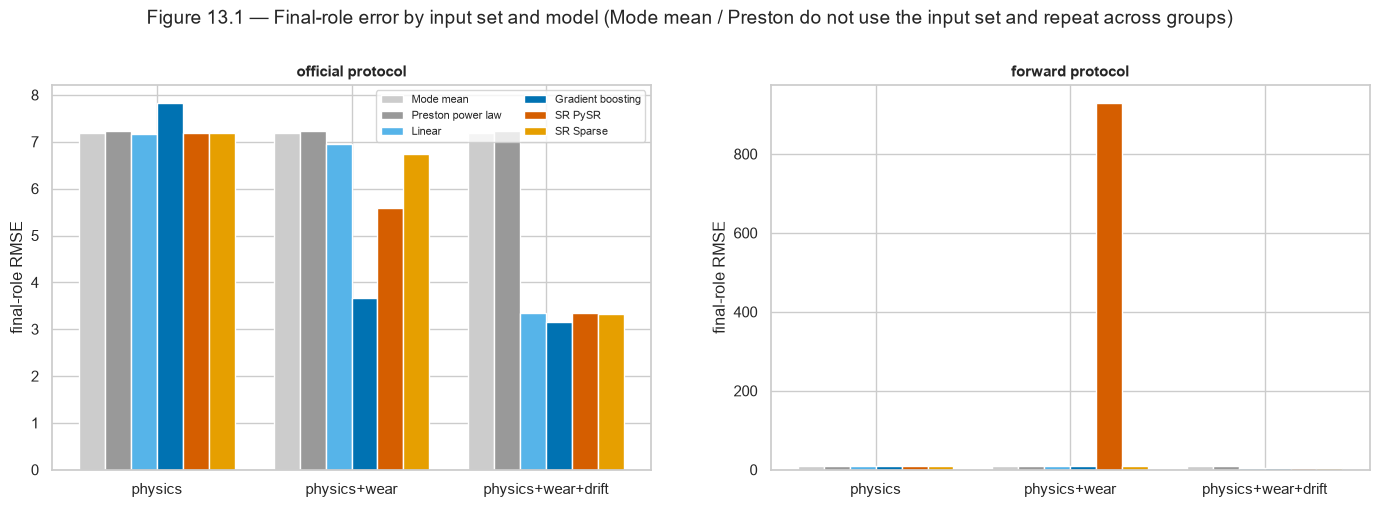

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=False)
order = ['Mode mean', 'Preston power law', 'Linear', 'Gradient boosting'] + [f'SR {e_}' for e_ in ENGINES]
colors = {'Mode mean': '#cccccc', 'Preston power law': '#999999', 'Linear': '#56B4E9', 'Gradient boosting': '#0072B2', 'SR PySR': '#D55E00', 'SR Sparse': '#E69F00'}
for ax, p in zip(axes, PROTOCOLS):
    f_ = final[final.protocol == p]
    x = np.arange(len(EXPERIMENTS)); w = .8 / len(order)
    for k, name in enumerate(order):
        vals = []
        for e in EXPERIMENTS:
            r = f_[(f_.model == name) & ((f_.experiment == e) | (f_.experiment == '-'))]
            vals.append(r.RMSE.iloc[0] if len(r) else np.nan)
        ax.bar(x + (k - len(order) / 2 + .5) * w, vals, w, label=name, color=colors.get(name, '#333'))
    ax.set_xticks(x); ax.set_xticklabels(list(EXPERIMENTS)); ax.set_ylabel('final-role RMSE'); ax.set_title(f'{p} protocol')
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle('Figure 13.1 — Final-role error by input set and model (Mode mean / Preston do not use the input set and repeat across groups)', y=1.03)
savefig(fig, '13_01_final_rmse')

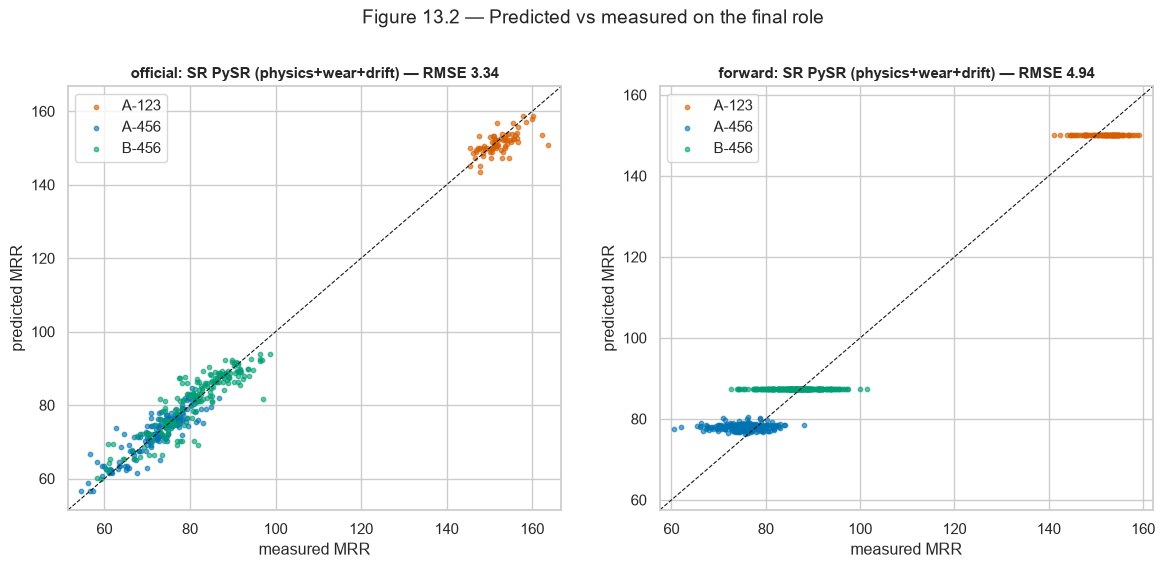

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, p in zip(axes, PROTOCOLS):
    fin = PROTOCOLS[p]['data'].query("ROLE == 'final'")
    pr = PRED[(p, MAIN_EXP, f'SR {main_engine}')]
    for m in MODES:
        k_ = (fin.MODE == m).values
        ax.scatter(fin.loc[k_, TARGET], pr[k_], s=10, alpha=.6, color=MODE_COLORS[m], label=m)
    lim = [fin[TARGET].min() - 3, fin[TARGET].max() + 3]
    ax.plot(lim, lim, 'k--', lw=.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('measured MRR'); ax.set_ylabel('predicted MRR')
    ax.set_title(f'{p}: SR {main_engine} ({MAIN_EXP}) — RMSE {rmse(fin[TARGET], pr):.2f}'); ax.legend()
fig.suptitle('Figure 13.2 — Predicted vs measured on the final role', y=1.02)
savefig(fig, '13_02_pred_vs_actual')

## 14. Residual diagnostics

Residuals (measured − predicted) of the main symbolic model are checked for patterns the equation misses: time, mode, the size of the prediction, and the shape of the error distribution.

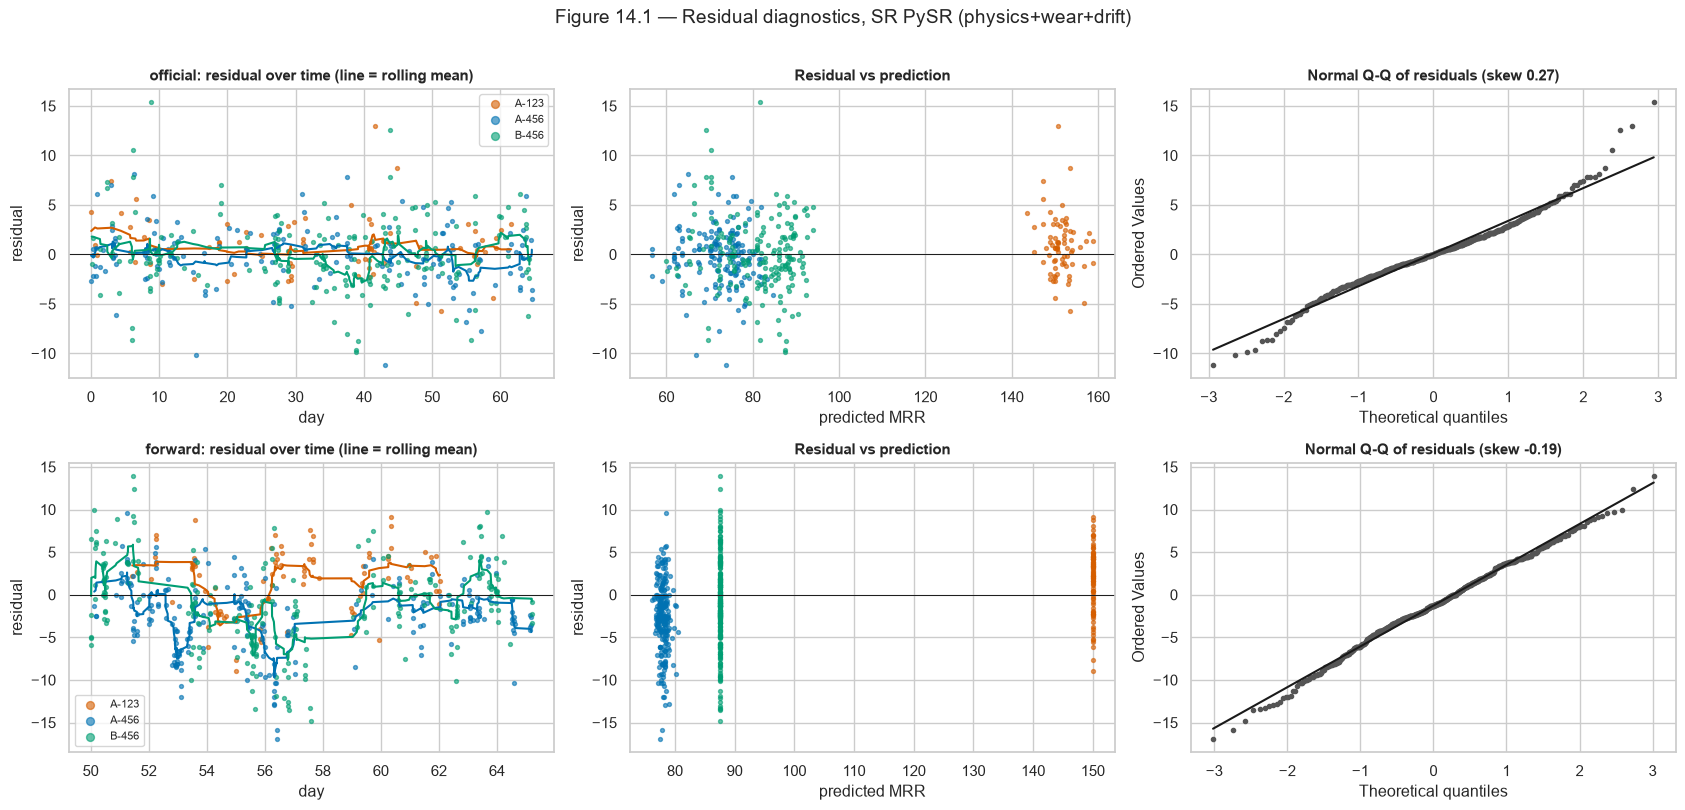

,protocol,mode,mean residual (bias),std,lag-1 autocorrelation
0,official,A-123,0.89,2.96,0.077
1,official,A-456,-0.1,2.979,0.128
2,official,B-456,-0.035,3.735,0.233
3,forward,A-123,1.668,3.815,0.606
4,forward,A-456,-2.662,4.168,0.557
5,forward,B-456,-1.04,5.127,0.627


In [21]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for i, p in enumerate(PROTOCOLS):
    fin = PROTOCOLS[p]['data'].query("ROLE == 'final'").copy()
    fin['resid'] = fin[TARGET] - PRED[(p, MAIN_EXP, f'SR {main_engine}')]
    fin = fin.sort_values('T_START')
    ax = axes[i, 0]
    for m in MODES:
        s_ = fin[fin.MODE == m]
        ax.scatter(s_.DAY, s_.resid, s=8, alpha=.6, color=MODE_COLORS[m], label=m)
        ax.plot(s_.DAY, s_.resid.rolling(15, center=True, min_periods=5).mean(), color=MODE_COLORS[m], lw=1.5)
    ax.axhline(0, color='k', lw=.7); ax.set_xlabel('day'); ax.set_ylabel('residual'); ax.set_title(f'{p}: residual over time (line = rolling mean)')
    ax.legend(fontsize=8, markerscale=2)
    ax = axes[i, 1]
    pr = fin[TARGET] - fin.resid
    for m in MODES:
        s_ = fin[fin.MODE == m]; ax.scatter(pr[s_.index], s_.resid, s=8, alpha=.6, color=MODE_COLORS[m])
    ax.axhline(0, color='k', lw=.7); ax.set_xlabel('predicted MRR'); ax.set_ylabel('residual'); ax.set_title('Residual vs prediction')
    ax = axes[i, 2]
    stats.probplot(fin.resid, dist='norm', plot=ax); ax.get_lines()[0].set(markersize=3, color='#555'); ax.get_lines()[1].set(color='k')
    ax.set_title(f'Normal Q-Q of residuals (skew {stats.skew(fin.resid):.2f})')
fig.suptitle(f'Figure 14.1 — Residual diagnostics, SR {main_engine} ({MAIN_EXP})', y=1.01)
fig.tight_layout(); savefig(fig, '14_01_residuals')

res_tab = []
for p in PROTOCOLS:
    fin = PROTOCOLS[p]['data'].query("ROLE == 'final'").sort_values('T_START').copy()
    fin['resid'] = fin[TARGET] - pd.Series(PRED[(p, MAIN_EXP, f'SR {main_engine}')], index=PROTOCOLS[p]['data'].query("ROLE == 'final'").index)
    for m in MODES:
        r_ = fin.loc[fin.MODE == m, 'resid'].values
        res_tab.append({'protocol': p, 'mode': m, 'mean residual (bias)': r_.mean(), 'std': r_.std(ddof=1),
                        'lag-1 autocorrelation': np.corrcoef(r_[:-1], r_[1:])[0, 1] if len(r_) > 3 else np.nan})
display(pd.DataFrame(res_tab).round(3))

**What to look for.** A rolling mean that wanders away from zero, or residuals that stay autocorrelated, means drift the equation does not capture. That is expected when the drift input is stale, as in the forward protocol, where predictions for the last days rely on a rate history that is 10–20 days old. A non-zero mean residual in one mode indicates bias for that regime.

## 15. Conclusions, limitations and next steps

The verdict on each hypothesis below is **computed** from the final-role results, so it updates automatically if the notebook is re-run with another preset or data.

In [22]:
def get(p, e, model, col='RMSE'):
    f_ = final[(final.protocol == p) & (final.model == model) & ((final.experiment == e) | (final.experiment == '-'))]
    return float(f_[col].iloc[0])

def cmpv(p, e, ref, eng=main_engine):
    r = comparisons[(comparisons.protocol == p) & (comparisons.experiment == e) & (comparisons['SR engine'] == eng) & (comparisons.vs == ref)].iloc[0]
    return r['ΔRMSE (SR − ref)'], r['CI low'], r['CI high'], r['verdict']

sr = f'SR {main_engine}'
h_rows = []
for p in PROTOCOLS:
    mm = get(p, 'physics', 'Mode mean')
    phys, wear, drift = get(p, 'physics', sr), get(p, 'physics+wear', sr), get(p, 'physics+wear+drift', sr)
    gb = get(p, MAIN_EXP, 'Gradient boosting')
    d1, l1, h1, v1 = cmpv(p, 'physics', 'Mode mean')
    d4, l4, h4, v4 = cmpv(p, MAIN_EXP, 'Gradient boosting')
    h_rows += [
        {'protocol': p, 'hypothesis': 'H1 Physics-only equations ≈ mode mean', 'evidence': f'RMSE {phys:.2f} vs {mm:.2f}; Δ = {d1:+.2f} [{l1:+.2f}, {h1:+.2f}]',
         'verdict': 'supported' if v1 != 'SR better' else 'not supported'},
        {'protocol': p, 'hypothesis': 'H2 Wear adds modest skill', 'evidence': f'RMSE physics {phys:.2f} → +wear {wear:.2f} ({100 * (wear / phys - 1):+.0f}%)',
         'verdict': 'supported' if wear < phys * 0.98 else 'not supported'},
        {'protocol': p, 'hypothesis': 'H3 Drift carries most skill', 'evidence': f'RMSE +wear {wear:.2f} → +drift {drift:.2f} ({100 * (drift / wear - 1):+.0f}%)',
         'verdict': 'supported' if drift < wear * 0.85 else 'not supported'},
        {'protocol': p, 'hypothesis': 'H4 Equation ≈ black box (same inputs)', 'evidence': f'SR {drift:.2f} vs GBM {gb:.2f}; Δ = {d4:+.2f} [{l4:+.2f}, {h4:+.2f}]',
         'verdict': 'supported' if v4 in ('no clear difference', 'negligible difference', 'SR better') else 'not supported'},
    ]
off_d, fwd_d = get('official', MAIN_EXP, sr), get('forward', MAIN_EXP, sr)
off_m, fwd_m = get('official', 'physics', 'Mode mean'), get('forward', 'physics', 'Mode mean')
h_rows.append({'protocol': 'both', 'hypothesis': 'H5 Skill holds forward in time',
               'evidence': f'improvement over mode mean: official {100 * (1 - off_d / off_m):.0f}% vs forward {100 * (1 - fwd_d / fwd_m):.0f}%',
               'verdict': 'supported' if (1 - fwd_d / fwd_m) > 0.5 * (1 - off_d / off_m) else 'not supported (skill shrinks sharply)'})
hyp = pd.DataFrame(h_rows)
display(hyp)

best_eq = chosen[(chosen.protocol == 'official') & (chosen.experiment == MAIN_EXP) & (chosen.engine == main_engine)].set_index('mode')
lines = '\n'.join(f'| {m} | `MRR = {best_eq.loc[m, "pretty"]}` | {int(best_eq.loc[m, "complexity"])} |' for m in MODES)
f_off = final[(final.protocol == 'official')]
summary_md = f"""**Engines run:** {', '.join(ENGINES)} ({PYSR_MSG if PYSR_OK else 'PySR not available on this machine; built-in sparse engine only'}). Preset `{PRESET}`.

**Main equations** (official protocol, inputs *{MAIN_EXP}*, engine {main_engine}; variables are scaled so 1.0 = typical):

| mode | equation | complexity |
|---|---|---|
{lines}

**Accuracy on the sealed official test set (RMSE):** mode mean {off_m:.2f} · Preston {get('official', 'physics', 'Preston power law'):.2f} · SR physics-only {get('official', 'physics', sr):.2f} · SR +wear {get('official', 'physics+wear', sr):.2f} · **SR +wear+drift {off_d:.2f}** · gradient boosting (same inputs) {get('official', MAIN_EXP, 'Gradient boosting'):.2f}.

**Forward-in-time (last 15 days, RMSE):** mode mean {fwd_m:.2f} · SR +wear+drift {fwd_d:.2f}.

**Hypotheses:** """ + '; '.join(f"{r.hypothesis.split(' ')[0]} ({r.protocol}) {r.verdict}" for r in hyp.itertuples()) + '.'
display(Markdown(summary_md))
(SR / 'summary.md').write_text(summary_md, encoding='utf-8')

,protocol,hypothesis,evidence,verdict
0,official,H1 Physics-only equations ≈ mode mean,"RMSE 7.18 vs 7.18; Δ = -0.00 [-0.00, +0.00]",supported
1,official,H2 Wear adds modest skill,RMSE physics 7.18 → +wear 5.60 (-22%),supported
2,official,H3 Drift carries most skill,RMSE +wear 5.60 → +drift 3.34 (-40%),supported
3,official,H4 Equation ≈ black box (same inputs),"SR 3.34 vs GBM 3.14; Δ = +0.19 [+0.01, +0.39]",not supported
4,forward,H1 Physics-only equations ≈ mode mean,"RMSE 8.45 vs 8.45; Δ = -0.00 [-0.00, -0.00]",supported
5,forward,H2 Wear adds modest skill,RMSE physics 8.45 → +wear 929.07 (+10890%),not supported
6,forward,H3 Drift carries most skill,RMSE +wear 929.07 → +drift 4.94 (-99%),supported
7,forward,H4 Equation ≈ black box (same inputs),"SR 4.94 vs GBM 5.22; Δ = -0.28 [-0.48, -0.07]",supported
8,both,H5 Skill holds forward in time,improvement over mode mean: official 54% vs fo...,supported


**Engines run:** PySR, Sparse (PySR 2.7.0 ready (13 s)). Preset `standard`.

**Main equations** (official protocol, inputs *physics+wear+drift*, engine PySR; variables are scaled so 1.0 = typical):

| mode | equation | complexity |
|---|---|---|
| A-123 | `MRR = 151.5*drift` | 3 |
| A-456 | `MRR = 74.43*drift` | 3 |
| B-456 | `MRR = 82.46*drift` | 3 |

**Accuracy on the sealed official test set (RMSE):** mode mean 7.18 · Preston 7.23 · SR physics-only 7.18 · SR +wear 5.60 · **SR +wear+drift 3.34** · gradient boosting (same inputs) 3.14.

**Forward-in-time (last 15 days, RMSE):** mode mean 8.45 · SR +wear+drift 4.94.

**Hypotheses:** H1 (official) supported; H2 (official) supported; H3 (official) supported; H4 (official) not supported; H1 (forward) supported; H2 (forward) not supported; H3 (forward) supported; H4 (forward) supported; H5 (both) supported.

865

**How to read the verdicts** (they are computed above; this guide explains what each outcome means)
* **H1, physics-only.** If the chosen physics equation collapses to a constant, or performs like the mode mean, then within a mode the recorded pressures, flows and speeds carry no usable signal, matching Notebook 1's Preston result. A physics equation that *did* beat the mode mean clearly would be worth checking for a clock-like proxy before believing it.
* **H2, wear.** Look at the official *and* forward rows together. Wear terms that help on the official split but not forward in time are mostly interpolating drift through the counters' saw-tooth phases (see the gradient-boosting warning in §5), not measuring wear. The dresser term's sign (§11) and selection frequency (§10) show whether a genuine wear effect remains.
* **H3, drift.** The drift level typically enters as a near-linear term, so the equation reads as "this mode's recent rate level, lightly corrected". That is a legitimate virtual-metrology formula, but its value depends on recent measurements being available.
* **H4, equation vs black box.** A small, statistically detectable gap (a few percent of RMSE) in favour of gradient boosting is the price of interpretability. A difference within ±2% is practically zero.
* **H5, forward in time.** The forward protocol's drift input is 10–25 days stale by the end of the final window, so it is a lower bound on what a regularly updated model would achieve.

**Note on within-mode R² in the forward protocol.** It can be negative even for good models. Within-mode R² compares against the *final period's own* mode means, which no model can know in advance when the level has shifted. RMSE and the paired comparisons are the reliable metrics there.

**Limitations**
* The data is observational and anonymised, with no units, so the equations are *descriptive* relations on this tool, not physical laws.
* Missing A-123 sensor values are filled with typical values, so for those runs the equations reduce to their typical-condition prediction.
* The official test set interleaves in time with training. The forward protocol is the more realistic estimate, but it rests on a single 15-day window.
* PySR is stochastic. Unless `REPRODUCIBLE_PYSR = True`, re-runs can return different equations of similar quality. The seed and bootstrap stability analysis (§10) quantifies this.
* The drift level depends on timely labels. In production, metrology delay would degrade it further than either protocol shows.

**Next steps**
1. Re-run with `PRESET = 'thorough'` and `REPRODUCIBLE_PYSR = True` before quoting final equations.
2. Add a recursive (online) protocol in which each prediction may use all labels measured before it, which is the realistic virtual-metrology setting.
3. Feed the missing context back into the search (consumable lot, recipe ID) if the data owner can supply it.
4. Use dimensional constraints (PySR `X_units`/`y_units`) once physical units are known.

## 16. Exports

* `outputs/sr/frozen_models.json`: every chosen equation, scaling constants, configuration and fingerprint
* `outputs/sr/final_metrics.csv`, `paired_comparisons.csv`, `stability_selections.csv`, `summary.md`
* `outputs/sr/all_candidates.csv`: every Pareto-front equation from every search, with fit and selection error
* `outputs/sr/predictions.csv`: final-role predictions of every model
* `outputs/sr/cmp_mrr_equations.py`: a **standalone predictor** (numpy + pandas only) for the main equations, verified below against the notebook's own predictions

In [23]:
cand.drop(columns=['loss'], errors='ignore').to_csv(SR / 'all_candidates.csv', index=False)
pred_rows = []
for (p, e, name), pr in PRED.items():
    fin = PROTOCOLS[p]['data'].query("ROLE == 'final'")
    pred_rows.append(pd.DataFrame({'protocol': p, 'experiment': e, 'model': name, 'RUN_ID': fin.RUN_ID.values, 'MODE': fin.MODE.values,
                                   'measured': fin[TARGET].values, 'predicted': pr}))
pd.concat(pred_rows).to_csv(SR / 'predictions.csv', index=False)

scale = PROTOCOLS['official']['scale']
eq_map = {m: best_eq.loc[m, 'equation'] for m in MODES}
inputs = EXPERIMENTS[MAIN_EXP]
module = f'''"""Standalone CMP removal-rate equations (generated by 02_cmp_symbolic_regression.ipynb).

Engine: {main_engine} | inputs: {MAIN_EXP} | protocol: official | fingerprint: {frozen['sha256'][:16]}
Usage:  import pandas as pd, cmp_mrr_equations as m;  m.predict(df)
df needs columns MODE plus the raw source features: {json.dumps({v: VARS.get(v, 'DRIFT_LEVEL (median rate of the 10 time-nearest measured runs, same mode)') for v in inputs})}
"""
import numpy as np, pandas as pd

SOURCE = {json.dumps({v: VARS.get(v, 'DRIFT_LEVEL') for v in inputs}, indent=4)}
MEDIANS = {json.dumps({m: {v: float(scale.loc[m, v]) for v in inputs} for m in MODES}, indent=4)}
EQUATIONS = {json.dumps(eq_map, indent=4)}
_F = {{'sqrt': np.sqrt, 'square': np.square, 'log': np.log, 'exp': np.exp, 'abs': np.abs}}

def predict(df):
    out = np.full(len(df), np.nan)
    for mode, expr in EQUATIONS.items():
        k = (df['MODE'] == mode).to_numpy()
        if not k.any(): continue
        env = dict(_F)
        for v, col in SOURCE.items():
            x = df.loc[k, col].astype(float)
            env[v] = (x.fillna(MEDIANS[mode][v]) / MEDIANS[mode][v]).to_numpy()
        with np.errstate(all='ignore'):
            out[k] = np.broadcast_to(np.asarray(eval(expr.replace('^', '**'), {{'__builtins__': {{}}}}, env), float), (int(k.sum()),))
    return out
'''
(SR / 'cmp_mrr_equations.py').write_text(module, encoding='utf-8')

import importlib.util
sys.dont_write_bytecode = True   # keep outputs/ free of __pycache__
spec = importlib.util.spec_from_file_location('cmp_mrr_equations', SR / 'cmp_mrr_equations.py'); mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
fin = PROTOCOLS['official']['data'].query("ROLE == 'final'").copy()
raw_in = fin[['MODE']].copy()
for v in inputs: raw_in[VARS.get(v, 'DRIFT_LEVEL')] = fin[v].values
standalone = mod.predict(raw_in)
assert np.allclose(standalone, PRED[('official', MAIN_EXP, sr)], rtol=1e-9, atol=1e-9), 'standalone predictor mismatch'
print('Standalone predictor reproduces the notebook predictions exactly on', len(fin), 'test runs.')
files = sorted(p for p in SR.rglob('*') if p.is_file() and 'cache' not in p.parts)
print(f'{len(files)} result files in outputs/sr (cache excluded):')
for p in files: print(f'  {p.relative_to(SR)}  ({p.stat().st_size / 1024:.0f} KB)')

Standalone predictor reproduces the notebook predictions exactly on 424 test runs.
16 result files in outputs/sr (cache excluded):
  all_candidates.csv  (117 KB)
  cmp_mrr_equations.py  (3 KB)
  figures\04_01_protocols.png  (192 KB)
  figures\08_pareto_forward.png  (320 KB)
  figures\08_pareto_official.png  (330 KB)
  figures\10_01_stability.png  (195 KB)
  figures\11_01_partial_dependence.png  (177 KB)
  figures\13_01_final_rmse.png  (64 KB)
  figures\13_02_pred_vs_actual.png  (132 KB)
  figures\14_01_residuals.png  (363 KB)
  final_metrics.csv  (5 KB)
  frozen_models.json  (12 KB)
  paired_comparisons.csv  (7 KB)
  predictions.csv  (926 KB)
  stability_selections.csv  (36 KB)
  summary.md  (1 KB)
